[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/notebooks/lecture3_notebook.ipynb)

# Blockchain Applications — Lecture 3: Volatility and Tail Risk

*Lecture notebook. Daniel Traian Pele, Bucharest University of Economic Studies.*

How much can a crypto position lose tomorrow, and how do we know that the risk model is right?
This notebook reproduces the estimates, tables and charts of Lecture 3:

1. volatility models: the exponentially weighted moving average (EWMA) and generalised autoregressive conditional heteroskedasticity (GARCH);
2. GARCH(1,1) estimates with Student-t errors and residual diagnostics;
3. Value-at-Risk (VaR) and Expected Shortfall (ES) for Bitcoin by four methods;
4. backtesting: the Kupiec and Christoffersen tests, the Basel traffic light and a check of ES;
5. out of sample: the forecasts of 18 September 2026 against the data of 19 September – 23 October 2026;
6. further material: asymmetric GARCH, news impact curves, risk contributions in a portfolio, the efficient frontier and further out-of-sample checks.

Data: daily closing prices from EOD Historical Data (EODHD), log returns in %, 1 January 2018 – 18 September 2026 for estimation and 19 September – 23 October 2026 for the out-of-sample evaluation; the portfolio sections use simple returns.

> **Working in Google Colab? Save your own copy first.**
> The Colab link opens a temporary copy: when you close the tab or the session times out, your changes are lost.
> Use **File → Save a copy in Drive** (it goes to the *Colab Notebooks* folder of your Google Drive) and work in that copy.
> Files you create while the notebook runs (CSV files, charts) are also temporary: set `SAVE_TO_DRIVE = True` in the next cell to keep them.

In [ ]:
# Optional (Colab only): keep the files you create in Google Drive
SAVE_TO_DRIVE = False   # set to True, run this cell and allow access to your Drive

import os
OUT_DIR = '.'
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/Blockchain_Applications/Lecture_3'
    os.makedirs(OUT_DIR, exist_ok=True)
print('Save your outputs to:', os.path.abspath(OUT_DIR))

In [2]:
# packages that are not preinstalled on Colab
import importlib, subprocess, sys
for pkg in ['arch']:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=True)

## Setup: packages, chart style and data

In [3]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [4]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

## Data: daily log returns

The daily log return in per cent is $r_t = 100\,\ln(P_t / P_{t-1})$, where $P_t$ is the closing price on day $t$.
Four assets: Bitcoin and Ethereum (traded every calendar day), the Standard & Poor's 500 stock index (S&P 500) and gold (spot price in US dollars).
For the S&P 500 and gold we keep Monday–Friday closes and remove repeated closes: the gold series has thin weekend bars, so Monday's return starts from Friday's close.
The sample runs from 1 January 2018 to 18 September 2026.
To express a daily volatility per year we multiply by $\sqrt{A}$, with $A = 365$ days for crypto and $A = 252$ trading days for the S&P 500 and gold.

In [5]:
from scipy import stats
from arch import arch_model
from statsmodels.stats.diagnostic import acorr_ljungbox

END = '2026-09-18'                      # last day of the estimation sample
ASSETS = {'Bitcoin': ('BTC-USD.CC', 365, BTC), 'Ethereum': ('ETH-USD.CC', 365, ETH),
          'S&P 500': ('GSPC.INDX', 252, BLUE), 'Gold': ('XAUUSD.FOREX', 252, GOLD)}


def closes(sym, end):
    # daily closes; S&P 500 and gold: Monday-Friday only, repeated closes removed
    p = daily(sym, end)
    if sym.endswith(('.INDX', '.FOREX')):
        p = p[p.index.dayofweek < 5]
        p = p[p.diff().ne(0)]
    return p


def log_returns(sym, start='2018-01-01'):
    # daily log returns in %, from `start` to END
    p = closes(sym, END)
    return (100 * np.log(p).diff()).dropna().loc[start:]


R = {k: log_returns(v[0]) for k, v in ASSETS.items()}
summary = pd.DataFrame({k: {'number of days': len(r), 'first day': r.index[0].date(), 'last day': r.index[-1].date(),
                            'mean daily return (%)': round(r.mean(), 3), 'sd of daily return (%)': round(r.std(), 3)}
                        for k, r in R.items()})
summary

,Bitcoin,Ethereum,S&P 500,Gold
number of days,3183,3183,2190,2269
first day,2018-01-01,2018-01-01,2018-01-02,2018-01-01
last day,2026-09-18,2026-09-18,2026-09-18,2026-09-18
mean daily return (%),0.055,0.039,0.048,0.053
sd of daily return (%),3.355,4.412,1.21,1.066


## 1. Volatility models

### Volatility clustering, again

Before any model, the evidence it has to explain: Bitcoin's daily log returns, and the autocorrelations of $r_t$, $|r_t|$ and $r_t^2$ at lags 1–30 days.
The dashed lines $\pm 1.96/\sqrt n$ are the 5% band for the autocorrelation of an independent series.

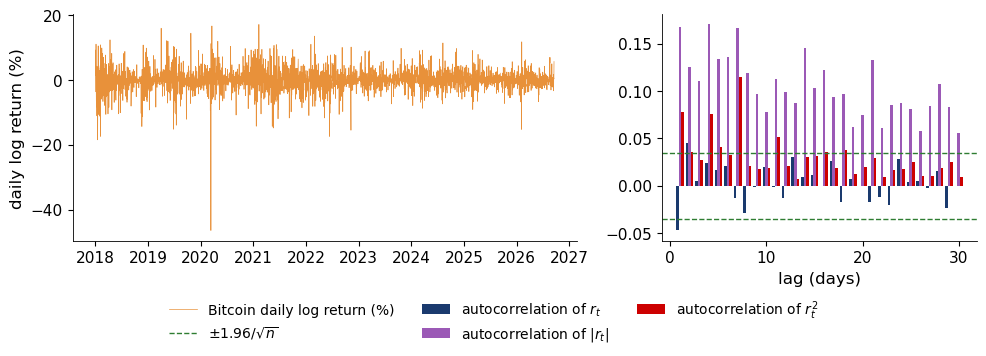

lags (of 30) outside the band: r_t 2, |r_t| 30, r_t^2 8
autocorrelation of |r_t| at lags 1-30: from 0.06 to 0.17
largest daily loss: -46.5% on 2020-03-12


In [6]:
from statsmodels.tsa.stattools import acf
rb = R['Bitcoin']
lags = np.arange(1, 31)
a_r, a_abs, a_sq = acf(rb, nlags=30)[1:], acf(rb.abs(), nlags=30)[1:], acf(rb ** 2, nlags=30)[1:]
band = 1.96 / np.sqrt(len(rb))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={'width_ratios': [1.6, 1]})
ax[0].plot(rb.index, rb.values, lw=0.5, color=BTC, label='Bitcoin daily log return (%)')
ax[0].set_ylabel('daily log return (%)')
ax[1].bar(lags - 0.27, a_r, width=0.27, color=BLUE, label='autocorrelation of $r_t$')
ax[1].bar(lags, a_abs, width=0.27, color=ETH, label='autocorrelation of $|r_t|$')
ax[1].bar(lags + 0.27, a_sq, width=0.27, color=RED, label='autocorrelation of $r_t^2$')
ax[1].axhline(band, color=GREEN, ls='--', lw=1, label=r'$\pm 1.96/\sqrt{n}$')
ax[1].axhline(-band, color=GREEN, ls='--', lw=1)
ax[1].set_xlabel('lag (days)')
legend_below(fig, ncol=3); fig.tight_layout(rect=(0, 0.14, 1, 1))
save_fig(fig, 'ba_l3_clustering')
print(f'lags (of 30) outside the band: r_t {int((np.abs(a_r) > band).sum())}, |r_t| {int((a_abs > band).sum())}, r_t^2 {int((a_sq > band).sum())}')
print(f'autocorrelation of |r_t| at lags 1-30: from {a_abs.min():.2f} to {a_abs.max():.2f}')
print(f'largest daily loss: {rb.min():.1f}% on {rb.idxmin().date()}')

Returns are hardly autocorrelated, while absolute returns are autocorrelated at every lag up to 30 days: large moves follow large moves (volatility clustering).
Squared returns show it less clearly, because a few extreme days, such as 12 March 2020, dominate them.

### From clustering to a model

We model the return as a constant mean plus a shock whose scale changes over time:

$$ r_t = \mu + \varepsilon_t, \qquad \varepsilon_t = \sigma_t z_t, \qquad z_t \overset{\text{i.i.d.}}{\sim} (0, 1). $$

Here i.i.d. means independent and identically distributed, and $\sigma_t^2 = \mathrm{Var}(r_t \mid \mathcal F_{t-1})$ is the **conditional variance**: the variance of tomorrow's return given the information $\mathcal F_{t-1}$ available at the end of day $t-1$.

The **exponentially weighted moving average** (EWMA, the RiskMetrics model) is the simplest recursion for $\sigma_t^2$:

$$ \sigma_t^2 = \lambda\,\sigma_{t-1}^2 + (1 - \lambda)\,\varepsilon_{t-1}^2 = (1 - \lambda)\sum_{j \ge 1}\lambda^{j-1}\varepsilon_{t-j}^2, \qquad \lambda = 0.94 . $$

The weights decay geometrically, with an effective memory of $1/(1-\lambda) \approx 17$ days.
EWMA has no long-run level: after a shock, its volatility forecast never returns to a mean.

The chart compares the EWMA weights $(1-\lambda)\lambda^{j-1}$ for $\lambda = 0.94$ and $\lambda = 0.97$ with a 30-day window of equal weights.

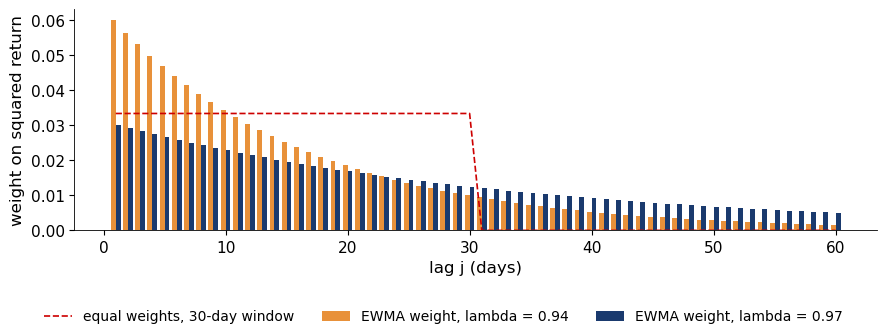

EWMA, lambda = 0.94: weight on yesterday = 6.0%, weight on day 30 = 1.00%
share of the total weight carried by the last 30 days = 84.4%
effective memory 1/(1 - lambda) = 16.7 days


In [7]:
j = np.arange(1, 61)
fig, ax = plt.subplots(figsize=(9, 3.4))
for lam_, col, dx in [(0.94, BTC, -0.2), (0.97, BLUE, 0.2)]:
    ax.bar(j + dx, (1 - lam_) * lam_ ** (j - 1), width=0.4, color=col, label=f'EWMA weight, lambda = {lam_}')
ax.plot(j, np.where(j <= 30, 1 / 30, 0), color=RED, ls='--', lw=1.2, label='equal weights, 30-day window')
ax.set_xlabel('lag j (days)'); ax.set_ylabel('weight on squared return')
legend_below(fig, ncol=3); fig.tight_layout(rect=(0, 0.12, 1, 1))
save_fig(fig, 'ba_l3_ewma_weights')

lam = 0.94
print(f'EWMA, lambda = {lam}: weight on yesterday = {100 * (1 - lam):.1f}%, weight on day 30 = {100 * (1 - lam) * lam ** 29:.2f}%')
print(f'share of the total weight carried by the last 30 days = {100 * (1 - lam ** 30):.1f}%')
print(f'effective memory 1/(1 - lambda) = {1 / (1 - lam):.1f} days')

With $\lambda = 0.94$, yesterday gets 6% of the weight and day 30 about 1%; the last 30 days together carry 84% of the weight.
There is no cliff at the end of the window: a crash 31 days ago does not suddenly drop out of the estimate, as it does with a rolling standard deviation.

### GARCH(1,1)

The **GARCH(1,1)** model of Bollerslev (1986) adds a constant to the EWMA recursion and frees the two weights:

$$ \sigma_t^2 = \omega + \alpha\,\varepsilon_{t-1}^2 + \beta\,\sigma_{t-1}^2, \qquad \omega > 0,\ \alpha, \beta \ge 0 . $$

- $\alpha$ measures the reaction to yesterday's news, $\beta$ the memory of yesterday's variance, and $\alpha + \beta$ the **persistence**.
- If $\alpha + \beta < 1$ the process is covariance-stationary, with long-run (unconditional) variance and $h$-step forecast
$$ \bar\sigma^2 = \frac{\omega}{1 - \alpha - \beta}, \qquad \mathrm{E}_t[\sigma_{t+h}^2] = \bar\sigma^2 + (\alpha + \beta)^{h-1}\big(\sigma_{t+1}^2 - \bar\sigma^2\big). $$
- The **half-life** of a volatility shock is $h_{1/2} = \ln 0.5 / \ln(\alpha + \beta)$ days.
- If $\alpha + \beta = 1$ the model is an **integrated GARCH** (IGARCH): shocks never die out and there is no finite long-run variance.
  With $\omega > 0$ the forecast rises linearly with the horizon, $\mathrm{E}_t[\sigma_{t+h}^2] = \sigma_{t+1}^2 + (h - 1)\,\omega$.
  EWMA is the special case $\omega = 0$, $\alpha = 1 - \lambda$, $\beta = \lambda$, with a flat forecast $\mathrm{E}_t[\sigma_{t+h}^2] = \sigma_{t+1}^2$.

### Student-t errors and maximum likelihood

Heavy tails remain after GARCH filtering, so we let $z_t$ follow a Student-t distribution with $\nu > 2$ degrees of freedom, rescaled to variance 1 (the model is called **GARCH-t**).
The log-likelihood of $\theta = (\mu, \omega, \alpha, \beta, \nu)$ is

$$ \ell(\theta) = \sum_{t=1}^{n}\Big[\ln\Gamma\big(\tfrac{\nu+1}{2}\big) - \ln\Gamma\big(\tfrac{\nu}{2}\big) - \tfrac12\ln\big(\pi(\nu - 2)\sigma_t^2\big) - \tfrac{\nu+1}{2}\ln\Big(1 + \frac{\varepsilon_t^2}{(\nu - 2)\sigma_t^2}\Big)\Big]. $$

Here $\Gamma(x) = \int_0^\infty u^{x-1}e^{-u}\,du$ is the gamma function, and each term is the log density of a Student-t scaled to variance $\sigma_t^2$.
$\sigma_t^2$ is computed recursively from $\theta$, and $\hat\theta = \arg\max \ell(\theta)$ is found by numerical optimisation, subject to $\omega > 0$, $\alpha, \beta \ge 0$, $\alpha + \beta \le 1$ and $\nu > 2$.
Standard errors come from the robust (sandwich) covariance of $\hat\theta$.
As $\nu \to \infty$ the Student-t becomes the Normal; $\nu$ close to 2 means very heavy tails.
Moments of order $k$ exist only for $k < \nu$: with $\nu \le 4$ the fourth moment $\mathrm{E}[z_t^4]$ is infinite, which matters for the diagnostics below.

The next cell fits GARCH(1,1)-t to each asset with the package `arch`, and also the asymmetric GJR version used later (Glosten, Jagannathan and Runkle, 1993).
It then recomputes the Bitcoin log-likelihood from the formula above, using the fitted $\hat\theta$ and the fitted $\hat\sigma_t$.

In [8]:
fits, gjr = {}, {}
for k, r in R.items():
    fits[k] = arch_model(r, mean='Constant', vol='GARCH', p=1, q=1, dist='t').fit(disp='off')
    gjr[k] = arch_model(r, mean='Constant', vol='GARCH', p=1, o=1, q=1, dist='t').fit(disp='off')

# the Student-t log-likelihood by hand, Bitcoin
from scipy.special import gammaln
g = fits['Bitcoin']
nu, mu_hat = g.params['nu'], g.params['mu']
eps, s2 = (R['Bitcoin'] - mu_hat).values, g.conditional_volatility.values ** 2
ll = np.sum(gammaln((nu + 1) / 2) - gammaln(nu / 2) - 0.5 * np.log(np.pi * (nu - 2) * s2)
            - (nu + 1) / 2 * np.log(1 + eps ** 2 / ((nu - 2) * s2)))
print(f'Bitcoin GARCH(1,1)-t log-likelihood from the formula: {ll:.2f}')
print(f'Bitcoin GARCH(1,1)-t log-likelihood reported by arch:  {g.loglikelihood:.2f}')

Bitcoin GARCH(1,1)-t log-likelihood from the formula: -7754.19
Bitcoin GARCH(1,1)-t log-likelihood reported by arch:  -7754.19


## 2. Estimates

### GARCH(1,1)-t estimates, 2018–2026

The table reports the estimates for the four assets, with robust standard errors (se) next to each parameter.
The persistence is $\hat\alpha + \hat\beta$, the half-life is $\ln 0.5/\ln(\hat\alpha + \hat\beta)$ in days (infinite when the persistence reaches 1), and the long-run volatility per year is $\sqrt{A\,\hat\omega/(1 - \hat\alpha - \hat\beta)}$, defined only when the persistence is below 1.

In [9]:
rows = {}
for k, g in fits.items():
    pr, se = g.params, g.std_err
    pers = pr['alpha[1]'] + pr['beta[1]']
    A = ASSETS[k][1]
    rows[k] = {'n (days)': len(R[k]),
               'omega': pr['omega'], 'se omega': se['omega'],
               'alpha': pr['alpha[1]'], 'se alpha': se['alpha[1]'],
               'beta': pr['beta[1]'], 'se beta': se['beta[1]'],
               'persistence alpha+beta': pers,
               'half-life (days)': np.log(0.5) / np.log(pers) if pers < 1 else np.inf,
               'nu (Student-t df)': pr['nu'], 'se nu': se['nu'],
               'long-run vol (% a year)': np.sqrt(A * pr['omega'] / (1 - pers)) if pers < 1 else np.nan,
               'mean mu (% a day)': pr['mu']}
est = pd.DataFrame(rows).T
est['n (days)'] = est['n (days)'].astype(int)
print('persistence alpha + beta, unrounded:', {k: f"{v:.10f}" for k, v in est['persistence alpha+beta'].items()})
est.round(3)

persistence alpha + beta, unrounded: {'Bitcoin': '1.0000000000', 'Ethereum': '1.0000000000', 'S&P 500': '0.9809963805', 'Gold': '0.9923313810'}


,n (days),omega,se omega,alpha,se alpha,beta,se beta,persistence alpha+beta,half-life (days),nu (Student-t df),se nu,long-run vol (% a year),mean mu (% a day)
Bitcoin,3183,0.144,0.058,0.076,0.012,0.924,0.012,1.000,inf,3.126,0.153,NaN,0.056
Ethereum,3183,0.550,0.373,0.117,0.038,0.883,0.042,1.000,inf,3.193,0.196,NaN,0.062
S&P 500,2190,0.035,0.009,0.162,0.022,0.819,0.021,0.981,36.127,5.845,0.707,21.614,0.111
Gold,2269,0.015,0.008,0.061,0.018,0.931,0.021,0.992,90.040,4.063,0.379,21.967,0.054


How to read the table:

- For Bitcoin and Ethereum $\hat\alpha + \hat\beta = 1$ to ten decimals: the estimate sits on the bound $\alpha + \beta \le 1$ imposed in estimation. With $\hat\omega > 0$ this is an IGARCH, with no finite long-run variance and no mean reversion of volatility in this sample.
- For the S&P 500 a shock to volatility halves in 36 trading days, and the long-run volatility is about 21.6% a year.
- $\hat\nu \approx 3.1$ for crypto and $5.9$ for the S&P 500: crypto shocks remain heavy-tailed even after the GARCH filter.

### Conditional volatility

The fitted conditional volatility $\hat\sigma_t$, annualised as $\hat\sigma_t\sqrt{A}$, for Bitcoin, Ethereum and the S&P 500.

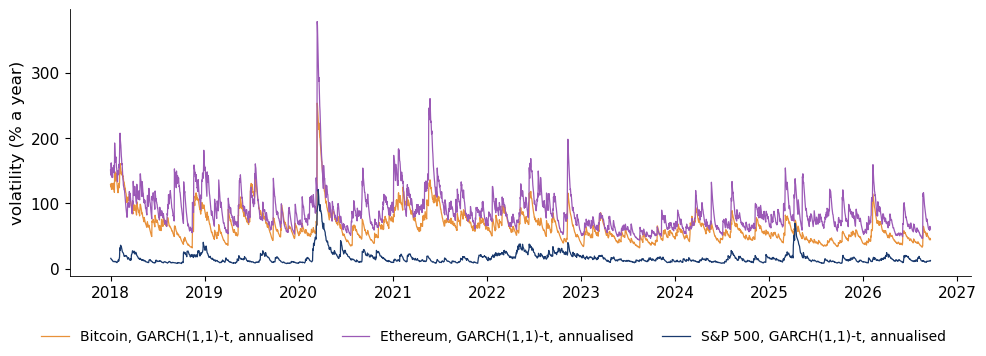

Bitcoin  annualised conditional volatility: maximum 253.5% on 2020-03-13, on 2026-09-18 44.6%, median 59.2%
Ethereum annualised conditional volatility: maximum 378.4% on 2020-03-13, on 2026-09-18 61.2%, median 81.6%
S&P 500  annualised conditional volatility: maximum 121.4% on 2020-03-17, on 2026-09-18 12.7%, median 14.1%


In [10]:
fig, ax = plt.subplots(figsize=(10, 3.6))
for k in ['Bitcoin', 'Ethereum', 'S&P 500']:
    v = fits[k].conditional_volatility * np.sqrt(ASSETS[k][1])
    ax.plot(v.index, v, color=ASSETS[k][2], lw=0.9, label=f'{k}, GARCH(1,1)-t, annualised')
ax.set_ylabel('volatility (% a year)')
legend_below(fig, ncol=3); fig.tight_layout(rect=(0, 0.1, 1, 1))
save_fig(fig, 'ba_l3_condvol')

for k in ['Bitcoin', 'Ethereum', 'S&P 500']:
    v = fits[k].conditional_volatility * np.sqrt(ASSETS[k][1])
    print(f'{k:8s} annualised conditional volatility: maximum {v.max():.1f}% on {v.idxmax().date()}, '
          f'on {v.index[-1].date()} {v.iloc[-1]:.1f}%, median {v.median():.1f}%')

### After a shock: volatility forecasts by horizon

Left: for the two assets with $\hat\alpha + \hat\beta < 1$ (S&P 500 and gold), suppose a shock doubles the variance; the chart shows the forecast variance $\mathrm{E}_t[\sigma^2_{t+h}]$ divided by the long-run variance, for horizons up to 250 days.

Right: Bitcoin, whose $\hat\alpha + \hat\beta = 1$ with $\hat\omega > 0$, has no long-run level. We plot the forecasts actually made on 18 September 2026: GARCH-t, whose variance forecast grows by $\hat\omega$ a day, and EWMA, whose forecast is flat.

S&P 500  persistence = 0.9810, half-life = 36.1 days, forecast variance / long-run after 250 days = 1.008
Gold     persistence = 0.9923, half-life = 90.0 days, forecast variance / long-run after 250 days = 1.147


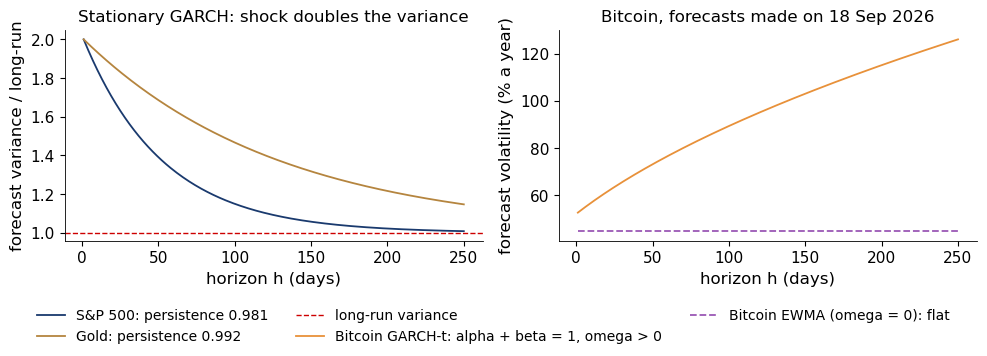

Bitcoin: omega = 0.144; largest gap between the arch forecast and v_1 + (h-1) omega: 2.4e-13
Bitcoin GARCH-t forecast volatility: h = 1: 52.7%, h = 35: 67.6%, h = 250: 126.0% a year
Bitcoin EWMA forecast volatility: 44.9% a year at every horizon


In [11]:
hz = np.arange(1, 251)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for k in ['S&P 500', 'Gold']:
    pr = fits[k].params; pers = pr['alpha[1]'] + pr['beta[1]']
    lr = pr['omega'] / (1 - pers)
    path_ = lr + pers ** (hz - 1) * (2 * lr - lr)
    ax[0].plot(hz, path_ / lr, color=ASSETS[k][2], label=f'{k}: persistence {pers:.3f}')
    print(f'{k:8s} persistence = {pers:.4f}, half-life = {np.log(0.5) / np.log(pers):.1f} days, '
          f'forecast variance / long-run after 250 days = {path_[-1] / lr:.3f}')
ax[0].axhline(1, color=RED, ls='--', lw=1, label='long-run variance')
ax[0].set_xlabel('horizon h (days)'); ax[0].set_ylabel('forecast variance / long-run')
ax[0].set_title('Stationary GARCH: shock doubles the variance')

gb = fits['Bitcoin']
fb = gb.forecast(horizon=len(hz), reindex=False).variance.values[-1]       # E_T[sigma^2_{T+h}], h = 1..250
v = R['Bitcoin'].iloc[:250].var()
for x in R['Bitcoin'].values:                                               # EWMA variance forecast for 19 Sep 2026
    v = lam * v + (1 - lam) * x ** 2
ax[1].plot(hz, np.sqrt(365 * fb), color=BTC, label='Bitcoin GARCH-t: alpha + beta = 1, omega > 0')
ax[1].plot(hz, np.full(len(hz), np.sqrt(365 * v)), color=ETH, ls='--', label='Bitcoin EWMA (omega = 0): flat')
ax[1].set_xlabel('horizon h (days)'); ax[1].set_ylabel('forecast volatility (% a year)')
ax[1].set_title('Bitcoin, forecasts made on 18 Sep 2026')
legend_below(fig, ncol=3); fig.tight_layout(rect=(0, 0.14, 1, 1))
save_fig(fig, 'ba_l3_term_structure')
om = gb.params['omega']
print(f'Bitcoin: omega = {om:.3f}; largest gap between the arch forecast and v_1 + (h-1) omega: {np.abs(fb - (fb[0] + (hz - 1) * om)).max():.1e}')
print(f'Bitcoin GARCH-t forecast volatility: h = 1: {np.sqrt(365 * fb[0]):.1f}%, h = 35: {np.sqrt(365 * fb[34]):.1f}%, h = 250: {np.sqrt(365 * fb[-1]):.1f}% a year')
print(f'Bitcoin EWMA forecast volatility: {np.sqrt(365 * v):.1f}% a year at every horizon')

For the S&P 500 a volatility shock halves in about 36 trading days and is gone after a year.
Gold, with persistence 0.992, has a half-life of about 90 days and is still about 15% above its long-run level after 250 days.
For Bitcoin there is no long-run level: the GARCH-t forecast keeps rising, from about 53% a year for the next day to about 126% at 250 days, while the EWMA forecast stays at 45%.
Only for EWMA is the variance of an $h$-day return exactly $h$ times today's variance, so that the $\sqrt h$ rule holds.

### Diagnostics: did the model remove the clustering?

If the model is right, the standardised residuals $\hat z_t = (r_t - \hat\mu)/\hat\sigma_t$ are i.i.d., so their squares should show no autocorrelation.
The Ljung–Box statistic with 10 lags, $Q(10)$, is $\chi^2_{10}$-distributed under no autocorrelation; its 5% critical value is 18.31.
That reference distribution needs a finite fourth moment $\mathrm{E}[z_t^4]$, which fails for a Student-t with $\nu \le 4$; here $\hat\nu \approx 3$ for crypto (about 4 for gold).
We therefore add two checks that need less:

- a **permutation p-value** for $Q(10)$ of $\hat z_t^2$: reshuffle $\hat z_t$ 999 times (under i.i.d. residuals every order is equally likely) and count how often the reshuffled $Q(10)$ is at least as large as the observed one;
- the Ljung–Box $Q(10)$ of $|\hat z_t|$, which needs only a finite variance of $|z_t|$, i.e. $\nu > 2$.

All p-values treat the estimated parameters as known.

In [12]:
lb = {}
for k, g in fits.items():
    rng = np.random.default_rng(1)
    z = g.std_resid.dropna()
    a = acorr_ljungbox(R[k] ** 2, lags=[10]); b = acorr_ljungbox(z ** 2, lags=[10]); c = acorr_ljungbox(z.abs(), lags=[10])
    q_obs = b['lb_stat'].iloc[0]
    q_perm = np.array([acorr_ljungbox(rng.permutation((z ** 2).values), lags=[10])['lb_stat'].iloc[0] for _ in range(999)])
    lb[k] = {'Q(10) of r^2': a['lb_stat'].iloc[0], 'Q(10) of z^2': q_obs, 'p-value z^2 (chi2)': b['lb_pvalue'].iloc[0],
             'p-value z^2 (permutation)': (1 + (q_perm >= q_obs).sum()) / 1000,
             'Q(10) of |z|': c['lb_stat'].iloc[0], 'p-value |z| (chi2)': c['lb_pvalue'].iloc[0]}
print('5% critical value of chi-square(10):', round(stats.chi2.ppf(0.95, 10), 2))
pd.DataFrame(lb).T.round(3)

5% critical value of chi-square(10): 18.31


,Q(10) of r^2,Q(10) of z^2,p-value z^2 (chi2),p-value z^2 (permutation),Q(10) of |z|,p-value |z| (chi2)
Bitcoin,97.648,5.509,0.855,0.232,24.486,0.006
Ethereum,131.803,8.794,0.552,0.291,10.535,0.395
S&P 500,2338.758,12.034,0.283,0.244,8.322,0.597
Gold,434.422,27.911,0.002,0.012,41.822,0.000


For crypto and the S&P 500, the usual test detects no autocorrelation in $\hat z_t^2$ at lags 1–10; this does not prove that all dependence is gone.
For Bitcoin the $\chi^2$ p-value (about 0.86) is far from the permutation p-value (about 0.2): with such heavy tails the usual reference is unreliable.
The check on $|\hat z_t|$ still finds dependence for Bitcoin (p-value below 0.01): GARCH(1,1)-t leaves some clustering in the size of the shocks.
For Ethereum and the S&P 500 no remaining dependence is detected; gold is rejected by all three checks, so a richer model (asymmetry, regime changes in 2025–2026) would be needed.
The $Q(10)$ of Bitcoin's $r_t^2$ is smaller than in Lecture 2 because the sample here starts in 2018, not 2014.

## 3. Value-at-Risk and Expected Shortfall

### Definitions

For the one-day return $r_{t+1}$ with conditional distribution $F_t$ and a small probability level $p$ (for example 1%), let $q_p = F_t^{-1}(p)$ be the $p$-quantile. Then

$$ \mathrm{VaR}_p = -q_p, \qquad \mathrm{ES}_p = -\mathrm{E}\big[r_{t+1} \mid r_{t+1} \le -\mathrm{VaR}_p\big] = \frac{1}{p}\int_0^p \mathrm{VaR}_u\,du . $$

- **Value-at-Risk** (VaR): the loss exceeded with probability $p$. We write "VaR 1%" for $p = 0.01$.
- **Expected Shortfall** (ES): the average loss on the days when the VaR is exceeded. We write "ES 2.5%" for $p = 0.025$.
- Artzner, Delbaen, Eber and Heath (1999): a **coherent** risk measure is monotone, translation-invariant, positively homogeneous and **subadditive**, $\rho(X + Y) \le \rho(X) + \rho(Y)$. ES is coherent; VaR is not subadditive in general, so diversification can appear to raise VaR.
- In the market-risk standard of the Basel Framework (MAR33), ES 2.5% replaced VaR 1% for the capital of banks that use internal models; VaR 1% remains in the backtesting of these models (MAR32).

Under the Normal distribution the two measures are almost equal, as the next cell shows; under heavy tails ES is larger.

In [13]:
p1, p25 = 0.01, 0.025
z1, z25 = stats.norm.ppf(p1), stats.norm.ppf(p25)
print(f'Normal: VaR 1%  = {-z1:.3f} x sigma')
print(f'Normal: ES 2.5% = {stats.norm.pdf(z25) / p25:.3f} x sigma')

Normal: VaR 1%  = 2.326 x sigma
Normal: ES 2.5% = 2.338 x sigma


### Four ways to compute VaR and ES

- **Normal**: $\mathrm{VaR}_p = -(\hat\mu + \hat\sigma\,\Phi^{-1}(p))$ and $\mathrm{ES}_p = -\hat\mu + \hat\sigma\,\varphi(\Phi^{-1}(p))/p$, where $\Phi$ and $\varphi$ are the standard Normal distribution function and density; here $\hat\mu$, $\hat\sigma$ are the mean and standard deviation of the whole 2018–2026 sample.
- **Historical simulation** (HS): $\mathrm{VaR}_p = -\hat q_p$, the empirical $p$-quantile of the last $W = 500$ returns; $\mathrm{ES}_p$ is minus the mean of the returns below $\hat q_p$.
- **EWMA**: the Normal formulas with $\hat\sigma_{t+1}$ from the EWMA recursion ($\lambda = 0.94$, started at the variance of the first 250 days) and $\hat\mu = 0$.
- **GARCH-t**: with $q = t_\nu^{-1}(p)$, the quantile of the standard Student-t, and the scale factor $s = \sqrt{(\nu - 2)/\nu}$ that brings the $t$ to variance 1,
$$ \mathrm{VaR}_p = -\big(\hat\mu + \hat\sigma_{t+1}\,s\,q\big), \qquad \mathrm{ES}_p = -\hat\mu + \hat\sigma_{t+1}\,s\,\frac{f_\nu(q)}{p}\,\frac{\nu + q^2}{\nu - 1}, $$
where $f_\nu$ is the Student-t density.

Over several days, $\mathrm{VaR}_h \approx \sqrt h\,\mathrm{VaR}_1$ holds only for i.i.d. Normal returns; with GARCH one uses the variance forecasts $\mathrm{E}_t[\sigma_{t+j}^2]$.

### Worked example: GARCH-t VaR and ES for Bitcoin

The one-step forecast made on 18 September 2026 gives $\hat\sigma_{t+1}$ for 19 September. The cell prints each step of the calculation.

In [14]:
g = fits['Bitcoin']
nu, m = g.params['nu'], g.params['mu']
sf = np.sqrt(g.forecast(horizon=1, reindex=False).variance.values[-1, 0])
sc = np.sqrt((nu - 2) / nu)
tq1, tq25 = stats.t.ppf(p1, nu), stats.t.ppf(p25, nu)


def es_factor(q, p, nu):
    # f_nu(q) / p * (nu + q^2) / (nu - 1): the ES multiplier of the standard Student-t
    return stats.t.pdf(q, nu) / p * (nu + q ** 2) / (nu - 1)


print(f'inputs on 18 Sep 2026: sigma_(t+1) = {sf:.3f}% a day, mu = {m:.3f}%, nu = {nu:.3f}')
print(f'scale factor s = sqrt((nu - 2)/nu) = {sc:.3f}')
print(f'VaR 1%:  q = t^-1(0.01) = {tq1:.3f};  VaR 1% = {-(m + sf * sc * tq1):.2f}%')
print(f'ES 2.5%: q = t^-1(0.025) = {tq25:.3f};  ES multiplier = {es_factor(tq25, p25, nu):.3f};  '
      f'ES 2.5% = {-m + sf * sc * es_factor(tq25, p25, nu):.2f}%')
print(f'Normal ES 2.5% with the same sigma: {sf * stats.norm.pdf(z25) / p25:.2f}%')

inputs on 18 Sep 2026: sigma_(t+1) = 2.761% a day, mu = 0.056%, nu = 3.126
scale factor s = sqrt((nu - 2)/nu) = 0.600
VaR 1%:  q = t^-1(0.01) = -4.398;  VaR 1% = 7.23%
ES 2.5%: q = t^-1(0.025) = -3.111;  ES multiplier = 4.844;  ES 2.5% = 7.97%
Normal ES 2.5% with the same sigma: 6.45%


### VaR and ES by method

The next cell computes the four forecasts for 19 September 2026.
Losses are given in log-return per cent and in US dollars (USD) for a long position of 1 million USD.
For VaR the conversion $10^6(1 - e^{-\mathrm{VaR}/100})$ is exact, because the USD loss is a monotone function of the return.
For ES it is not: the ES in USD is the mean of the USD loss $L = 10^6(1 - e^{r/100})$ over the 2.5% tail of $r$,
$\mathrm{ES}^{\mathrm{USD}} = \frac{1}{p}\int_0^p 10^6\big(1 - e^{Q(u)/100}\big)\,du$, where $Q$ is the return quantile function of each method (for historical simulation, the mean of $L$ over the tail returns).
The last column shows the inexact shortcut $10^6(1 - e^{-\mathrm{ES}/100})$ for comparison.

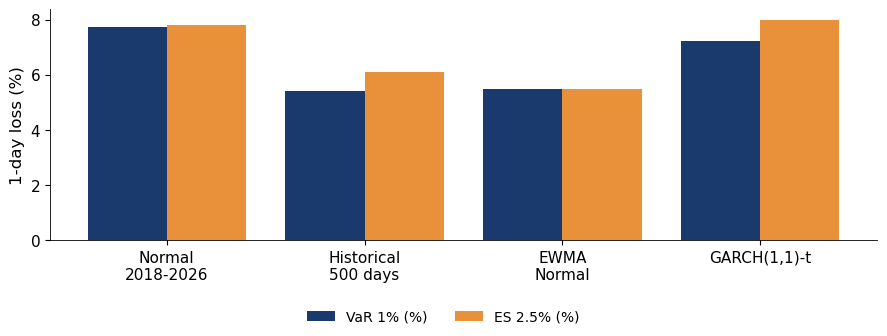

Bitcoin, 1-day VaR 1% and ES 2.5% for 19 September 2026
largest / smallest VaR 1% across methods = 1.43


,VaR 1% (%),ES 2.5% (%),"VaR, USD per 1m","ES, USD per 1m","ES, USD per 1m, shortcut (inexact)",ES / VaR
"Normal, 2018-2026",7.75,7.79,74567.0,74862.0,74923.0,1.00
"Historical simulation, 500 days",5.43,6.12,52854.0,59002.0,59360.0,1.13
"EWMA, lambda 0.94, Normal",5.47,5.49,53208.0,53433.0,53463.0,1.00
"GARCH(1,1)-t",7.23,7.97,69753.0,75761.0,76614.0,1.10


In [15]:
r = R['Bitcoin']
out = {}
mu_, s_ = r.mean(), r.std()
out['Normal, 2018-2026'] = (-(mu_ + s_ * z1), -mu_ + s_ * stats.norm.pdf(z25) / p25)
h = r.iloc[-500:]
out['Historical simulation, 500 days'] = (-h.quantile(p1), -h[h <= h.quantile(p25)].mean())
v = r.iloc[:250].var()
for x in r.values:
    v = lam * v + (1 - lam) * x ** 2
out['EWMA, lambda 0.94, Normal'] = (-np.sqrt(v) * z1, np.sqrt(v) * stats.norm.pdf(z25) / p25)
out['GARCH(1,1)-t'] = (-(m + sf * sc * tq1), -m + sf * sc * es_factor(tq25, p25, nu))

from scipy.integrate import quad


def es_usd(Q, p=p25):
    # mean USD loss per 1m over the p-tail: (1/p) int_0^p 1e6 (1 - exp(Q(u)/100)) du
    return 1e6 * quad(lambda u: 1 - np.exp(Q(u) / 100), 0, p, limit=200)[0] / p


V = pd.DataFrame(out, index=['VaR 1% (%)', 'ES 2.5% (%)']).T
V['VaR, USD per 1m'] = (1e6 * (1 - np.exp(-V['VaR 1% (%)'] / 100))).round(0)
s_ew = np.sqrt(v)
V['ES, USD per 1m'] = np.round([es_usd(lambda u: mu_ + s_ * stats.norm.ppf(u)),
                                1e6 * (1 - np.exp(h[h <= h.quantile(p25)] / 100)).mean(),
                                es_usd(lambda u: s_ew * stats.norm.ppf(u)),
                                es_usd(lambda u: m + sf * sc * stats.t.ppf(u, nu))], 0)
V['ES, USD per 1m, shortcut (inexact)'] = (1e6 * (1 - np.exp(-V['ES 2.5% (%)'] / 100))).round(0)
V['ES / VaR'] = V['ES 2.5% (%)'] / V['VaR 1% (%)']

fig, ax = plt.subplots(figsize=(9, 3.4))
xx = np.arange(len(V))
ax.bar(xx - 0.2, V['VaR 1% (%)'], width=0.4, color=BLUE, label='VaR 1% (%)')
ax.bar(xx + 0.2, V['ES 2.5% (%)'], width=0.4, color=BTC, label='ES 2.5% (%)')
ax.set_xticks(xx); ax.set_xticklabels(['Normal\n2018-2026', 'Historical\n500 days', 'EWMA\nNormal', 'GARCH(1,1)-t'])
ax.set_ylabel('1-day loss (%)')
legend_below(fig, ncol=2); fig.tight_layout(rect=(0, 0.1, 1, 1))
save_fig(fig, 'ba_l3_var_methods')

print('Bitcoin, 1-day VaR 1% and ES 2.5% for 19 September 2026')
print(f'largest / smallest VaR 1% across methods = {V["VaR 1% (%)"].max() / V["VaR 1% (%)"].min():.2f}')
V.round(2)

The Normal and EWMA methods give $\mathrm{ES}_{2.5\%} \approx \mathrm{VaR}_{1\%}$: they ignore the heavy tail.
For GARCH-t, ES exceeds VaR by about 10%, the cost of the heavy tail ($\hat\nu \approx 3.1$); for historical simulation by about 13%.
The four VaR figures differ by up to 43%: the choice of model is itself a source of risk (**model risk**).

## 4. Backtesting

### The hit sequence and the tests

A **hit** (violation) on day $t$ is $I_t = \mathbb{1}\{r_t < -\mathrm{VaR}_{p,t}\}$. For a correct VaR model the hits are i.i.d. Bernoulli($p$).

- **Unconditional coverage** (Kupiec, 1995): with $x$ hits in $n$ days and $\hat\pi = x/n$, the likelihood ratio (LR)
$$ \mathrm{LR}_{uc} = -2\ln\frac{(1 - p)^{n - x}p^{x}}{(1 - \hat\pi)^{n - x}\hat\pi^{x}} \sim \chi^2_1 . $$
- **Independence** (Christoffersen, 1998): $n_{ij}$ is the number of days in state $j$ after a day in state $i$ (1 = hit), and $\hat\pi_{ij} = n_{ij}/(n_{i0} + n_{i1})$:
$$ \mathrm{LR}_{ind} = -2\ln\frac{(1 - \hat\pi)^{n_{00} + n_{10}}\,\hat\pi^{n_{01} + n_{11}}}{(1 - \hat\pi_{01})^{n_{00}}\hat\pi_{01}^{n_{01}}(1 - \hat\pi_{11})^{n_{10}}\hat\pi_{11}^{n_{11}}} \sim \chi^2_1 . $$
- **Conditional coverage**: $\mathrm{LR}_{cc} = \mathrm{LR}_{uc} + \mathrm{LR}_{ind} \sim \chi^2_2$.
- **Basel traffic light**, 250 days at VaR 1%: green zone 0–4 hits, amber 5–9, red 10 or more.

### The rolling forecasts

The test period is 1 January 2020 – 18 September 2026; Bitcoin returns from 2015 provide the estimation windows. For each day $t$ the four methods use only data up to $t-1$:

- Normal on the last 250 days; HS on the last 500 days; EWMA ($\lambda = 0.94$) run over the whole history;
- GARCH-t re-estimated every 21 days on all data up to the previous day, then filtered daily with the fixed parameters.

The cell also stores the 2.5% quantile and the ES 2.5% forecasts, used in the ES check further below. The GARCH re-estimation takes about a minute.

In [16]:
full = (100 * np.log(daily('BTC-USD.CC', END)).diff()).dropna().loc['2015-01-01':]
test = full.loc['2020-01-01':]
idx = test.index
METHODS = ['Normal 250', 'HS 500', 'EWMA', 'GARCH-t']
pred = {m_: pd.Series(np.nan, index=idx) for m_ in METHODS}      # VaR 1% forecasts
pred_es = {m_: pd.Series(np.nan, index=idx) for m_ in METHODS}   # ES 2.5% forecasts
q25f = {m_: pd.Series(np.nan, index=idx) for m_ in METHODS}      # VaR 2.5% forecasts (minus the 2.5% quantile)
loc = {t_: i for i, t_ in enumerate(full.index)}

# EWMA: the variance forecast for day t, made at the end of day t-1
ew = pd.Series(index=full.index, dtype=float)
v = full.iloc[:250].var()
for t_, x in full.items():
    ew[t_] = v
    v = lam * v + (1 - lam) * x ** 2

for t_ in idx:
    i = loc[t_]
    w250, w500 = full.iloc[i - 250:i], full.iloc[i - 500:i]
    pred['Normal 250'][t_] = -(w250.mean() + w250.std() * z1)
    q25f['Normal 250'][t_] = -(w250.mean() + w250.std() * z25)
    pred_es['Normal 250'][t_] = -w250.mean() + w250.std() * stats.norm.pdf(z25) / p25
    pred['HS 500'][t_] = -w500.quantile(p1)
    q25f['HS 500'][t_] = -w500.quantile(p25)
    pred_es['HS 500'][t_] = -w500[w500 <= w500.quantile(p25)].mean()
    pred['EWMA'][t_] = -np.sqrt(ew[t_]) * z1
    q25f['EWMA'][t_] = -np.sqrt(ew[t_]) * z25
    pred_es['EWMA'][t_] = np.sqrt(ew[t_]) * stats.norm.pdf(z25) / p25

# GARCH-t: re-estimate every 21 days on data up to t-1, filter daily with fixed parameters
for b0 in range(0, len(idx), 21):
    t0 = idx[b0]; hist = full.iloc[:loc[t0]]
    prm = arch_model(hist, mean='Constant', vol='GARCH', p=1, q=1, dist='t').fit(disp='off').params
    seg = full.iloc[:loc[idx[min(b0 + 20, len(idx) - 1)]] + 1]
    fc = arch_model(seg, mean='Constant', vol='GARCH', p=1, q=1, dist='t').fix(prm).forecast(
        horizon=1, start=hist.index[-1], reindex=False)
    nu_b = prm['nu']; sc_b = np.sqrt((nu_b - 2) / nu_b)
    for orig, vv in fc.variance.iloc[:, 0].items():      # forecast for the day after `orig`
        j_ = loc[orig] + 1
        if j_ >= len(full) or full.index[j_] < t0:
            continue
        tday, sd = full.index[j_], np.sqrt(vv)
        q = stats.t.ppf(p25, nu_b)
        pred['GARCH-t'][tday] = -(prm['mu'] + sd * sc_b * stats.t.ppf(p1, nu_b))
        q25f['GARCH-t'][tday] = -(prm['mu'] + sd * sc_b * q)
        pred_es['GARCH-t'][tday] = -prm['mu'] + sd * sc_b * es_factor(q, p25, nu_b)

print(f'test period {idx[0].date()} - {idx[-1].date()}: {len(idx)} days; expected hits at 1% = {p1 * len(idx):.1f}')
print('days with a forecast:', {m_: int(pred[m_].notna().sum()) for m_ in METHODS})

test period 2020-01-01 - 2026-09-18: 2453 days; expected hits at 1% = 24.5
days with a forecast: {'Normal 250': 2453, 'HS 500': 2453, 'EWMA': 2453, 'GARCH-t': 2453}


### Worked example: the Kupiec test

We apply the formula step by step to the Normal VaR on a 250-day window.

In [17]:
def kupiec(I, p):
    n, x = len(I), int(I.sum())
    ph = x / n
    l0 = (n - x) * np.log(1 - p) + x * np.log(p)
    l1 = (n - x) * np.log(1 - ph) + (x * np.log(ph) if x > 0 else 0)
    LR = -2 * (l0 - l1)
    return x, ph, l0, l1, LR, stats.chi2.sf(LR, 1)


def christoffersen(I):
    I = I.astype(int).values
    a, b = I[:-1], I[1:]
    n00, n01 = np.sum((a == 0) & (b == 0)), np.sum((a == 0) & (b == 1))
    n10, n11 = np.sum((a == 1) & (b == 0)), np.sum((a == 1) & (b == 1))
    p01 = n01 / (n00 + n01) if n00 + n01 else 0
    p11 = n11 / (n10 + n11) if n10 + n11 else 0
    p_ = (n01 + n11) / (n00 + n01 + n10 + n11)
    def ll(p, k0, k1):
        return (k0 * np.log(1 - p) if k0 else 0) + (k1 * np.log(p) if k1 and p > 0 else 0)
    LR = -2 * (ll(p_, n00 + n10, n01 + n11) - ll(p01, n00, n01) - ll(p11, n10, n11))
    return LR, stats.chi2.sf(LR, 1), n11


I = test < -pred['Normal 250']
x, ph, l0, l1, LR, pv = kupiec(I, p1)
n = len(I)
print(f'Normal VaR, 250-day window: n = {n} days, x = {x} hits, expected n*p = {n * p1:.1f}, pi_hat = {ph:.4f}')
print(f'ln L0 = {n - x} ln 0.99 + {x} ln 0.01 = {l0:.1f}')
print(f'ln L1 = {n - x} ln(1 - {ph:.4f}) + {x} ln {ph:.4f} = {l1:.1f}')
print(f'LR_uc = -2 (ln L0 - ln L1) = {LR:.2f};  5% critical value of chi-square(1) = {stats.chi2.ppf(0.95, 1):.2f};  p-value = {pv:.4f}')

Normal VaR, 250-day window: n = 2453 days, x = 45 hits, expected n*p = 24.5, pi_hat = 0.0183
ln L0 = 2408 ln 0.99 + 45 ln 0.01 = -231.4
ln L1 = 2408 ln(1 - 0.0183) + 45 ln 0.0183 = -224.5
LR_uc = -2 (ln L0 - ln L1) = 13.84;  5% critical value of chi-square(1) = 3.84;  p-value = 0.0002


The model is rejected: almost twice as many hits as promised.
For a bank this is a capital issue, since Basel multiplies market-risk capital by a factor that rises with the number of exceptions.

### Backtest: Bitcoin, 1-day VaR 1%, 2020–2026

For each method the table gives the number of hits, the hit rate, the three likelihood-ratio statistics with their p-values, the number of hits in the last 250 days with the traffic-light zone, and the mean VaR over the test period.

In [18]:
last250 = idx[-250:]
bt = {}
for m_ in METHODS:
    P = pred[m_].dropna(); rr = test.loc[P.index]
    I = rr < -P
    x, ph, _, _, LRuc, puc = kupiec(I, p1)
    LRind, pind, n11 = christoffersen(I)
    LRcc = LRuc + LRind
    tl = int(I.loc[I.index.isin(last250)].sum())
    bt[m_] = {'days': len(P), 'hits': x, 'hit rate (%)': 100 * ph, 'LR_uc': LRuc, 'p uc': puc,
              'LR_ind': LRind, 'p ind': pind, 'LR_cc': LRcc, 'p cc': stats.chi2.sf(LRcc, 2),
              'hits, last 250 days': tl, 'zone': 'green' if tl <= 4 else ('amber' if tl <= 9 else 'red'),
              'mean VaR 1% (%)': P.mean()}
B = pd.DataFrame(bt).T
num = B.columns.drop('zone')
B[num] = B[num].astype(float).round(3)
B[['days', 'hits', 'hits, last 250 days']] = B[['days', 'hits', 'hits, last 250 days']].astype(int)
B

,days,hits,hit rate (%),LR_uc,p uc,LR_ind,p ind,LR_cc,p cc,"hits, last 250 days",zone,mean VaR 1% (%)
Normal 250,2453,45,1.834,13.842,0.000,0.036,0.850,13.878,0.001,5,amber,7.159
HS 500,2453,25,1.019,0.009,0.924,1.289,0.256,1.298,0.523,3,green,8.635
EWMA,2453,51,2.079,22.006,0.000,0.004,0.952,22.010,0.000,5,amber,6.784
GARCH-t,2453,28,1.141,0.474,0.491,0.954,0.329,1.428,0.490,2,green,8.118


Normal and EWMA fail unconditional coverage, with almost twice as many hits as promised.
HS and GARCH-t pass all three tests; GARCH-t reacts to news, while HS needs a higher average VaR for the same coverage.

### Violations through time

Bitcoin daily returns with the negative VaR 1% lines of HS and GARCH-t; red dots mark the GARCH-t hits.

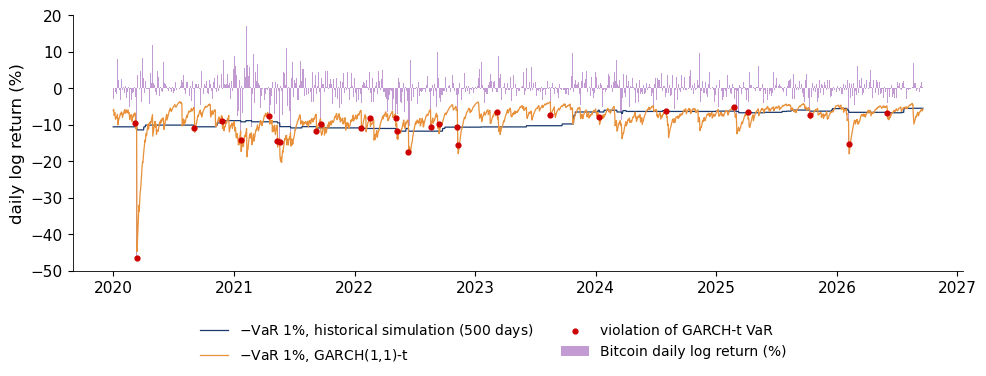

In [19]:
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(test.index, test.values, width=1.0, color=ETH, alpha=0.6, label='Bitcoin daily log return (%)')
ax.plot(idx, -pred['HS 500'], color=BLUE, lw=0.9, label='$-$VaR 1%, historical simulation (500 days)')
ax.plot(idx, -pred['GARCH-t'], color=BTC, lw=0.9, label='$-$VaR 1%, GARCH(1,1)-t')
Ig = test < -pred['GARCH-t']
ax.scatter(test.index[Ig], test[Ig], color=RED, s=12, zorder=5, label='violation of GARCH-t VaR')
ax.set_ylim(-50, 20); ax.set_ylabel('daily log return (%)')
legend_below(fig, ncol=2); fig.tight_layout(rect=(0, 0.16, 1, 1))
save_fig(fig, 'ba_l3_backtest')

The HS line moves in steps and lags the market; the GARCH-t line widens within days after a shock.
The GARCH-t hits are spread over time, with no clustering, in line with the independence test.

### Checking Expected Shortfall

ES cannot be backtested on its own the way VaR is (it is not elicitable).
A simple check in the spirit of McNeil and Frey (2000): on the days when the return falls below the forecast 2.5% quantile, compare the realised loss with the predicted ES,

$$ \bar R = \frac{1}{N}\sum_{t:\,r_t < -\mathrm{VaR}_{2.5\%,t}} \frac{-r_t}{\mathrm{ES}_{2.5\%,t}}, \qquad \text{correct model: } \bar R \approx 1 . $$

A ratio near 1 is not enough on its own: we add a 95% bootstrap interval for $\bar R$ (9 999 resamples of the $N$ ratios, tail days treated as independent) and the Kupiec test of the 2.5% tail-day rate.

In [20]:
es_rows = {}
for m_ in METHODS:
    hit = test < -q25f[m_]
    loss, esp = -test[hit], pred_es[m_][hit]
    es_rows[m_] = {'tail days': int(hit.sum()), 'tail-day rate (%)': 100 * hit.mean(),
                   'mean realised loss (%)': loss.mean(), 'mean predicted ES 2.5% (%)': esp.mean(),
                   'R bar = mean(loss / ES)': (loss / esp).mean()}
    rat = (loss / esp).values
    rng = np.random.default_rng(2)
    bs = np.array([rng.choice(rat, len(rat)).mean() for _ in range(9999)])
    es_rows[m_]['95% interval, low'], es_rows[m_]['95% interval, high'] = np.quantile(bs, [0.025, 0.975])
    x25, _, _, _, LR25, p25v = kupiec(hit, p25)
    es_rows[m_]['Kupiec LR at 2.5%'], es_rows[m_]['Kupiec p at 2.5%'] = LR25, p25v
E = pd.DataFrame(es_rows).T.round(3)
E['tail days'] = E['tail days'].astype(int)
print(f'expected tail days: 0.025 x {len(idx)} = {p25 * len(idx):.1f}')
E

expected tail days: 0.025 x 2453 = 61.3


,tail days,tail-day rate (%),mean realised loss (%),mean predicted ES 2.5% (%),R bar = mean(loss / ES),"95% interval, low","95% interval, high",Kupiec LR at 2.5%,Kupiec p at 2.5%
Normal 250,71,2.894,8.480,6.723,1.262,1.128,1.442,1.491,0.222
HS 500,61,2.487,9.045,9.136,1.001,0.893,1.148,0.002,0.966
EWMA,76,3.098,7.940,6.109,1.305,1.166,1.488,3.351,0.067
GARCH-t,76,3.098,7.919,8.035,0.968,0.875,1.094,3.351,0.067


With Normal-based ES, realised tail losses are 26–31% larger than predicted, and both intervals lie above 1.
For HS and GARCH-t the intervals contain 1: no evidence against their ES level in this sample.
GARCH-t has 76 days beyond its 2.5% quantile against 61.3 expected; the Kupiec test at 2.5% does not reject at 5% (p-value about 0.07).
This is a preliminary diagnostic, not a formal ES backtest.

## 5. Out of sample: 19 September – 23 October 2026

### The forecasts meet new data

All estimates so far use data up to 18 September 2026 (day $T$). We now take the returns of the next five weeks, to 23 October 2026, and ask how the forecasts made on 18 September performed.

The GARCH-t parameters are **frozen** on 18 September. Only the GARCH filter is updated with each new return,

$$ \hat\sigma^2_{t|t-1} = \hat\omega + \hat\alpha\,(r_{t-1} - \hat\mu)^2 + \hat\beta\,\hat\sigma^2_{t-1|t-2}, \qquad t = T+1, \dots, T+H . $$

Two questions:

- Was the **level** of volatility right? We compare the realised volatility $\sqrt{A\,\overline{r^2}}$, where $\overline{r^2}$ is the mean squared return over the window, with the 18 September forecast for the window, $\sqrt{A\,\frac1H\sum_{h=1}^{H} \mathrm{E}_T\sigma^2_{T+h}}$.
- Did the VaR hold? We count the hits and compare them with the expected number $np$.

The window has 35 calendar days for crypto and 25 trading days for the S&P 500 and gold, so a third question is how much such a short window can tell us.

The methods are not all updated in the same way:

| Method | parameters | volatility state | estimation window |
|---|---|---|---|
| GARCH-t | fixed on 18 Sep | updated daily with $r_{t-1}$ | 2018 – 18 Sep, fixed |
| EWMA, $\lambda = 0.94$ | $\lambda$ fixed | updated daily with $r_{t-1}$ | none |
| Normal, VaR rolled forward | mean and sd re-estimated daily | none | 2018 to $t-1$, expanding |
| Normal, volatility table | fixed on 18 Sep | none | 2018 – 18 Sep, fixed |
| HS, 500 days | none | none | last 500 days to $t-1$, rolling |

The volatility-level table below uses forecasts made on 18 September for the whole window, never updated; the one-step forecasts (VaR rolled forward, QLIKE, PIT) are updated as in the table.

The table reports, per year and in %: the return over the window; the GARCH-t forecast for 19 September ($\hat\sigma_{T+1}$); the GARCH-t forecast averaged over the window; the EWMA forecast for 19 September; the Normal volatility of 2018–2026; and the realised volatility.

In [21]:
T0, T1 = pd.Timestamp(END), pd.Timestamp('2026-10-23')
oos_rows, paths, onestep, pits, qlike_d = {}, {}, {}, {}, {}
for k, (sym, A, col) in ASSETS.items():
    r_all = (100 * np.log(closes(sym, T1)).diff()).dropna().loc['2018-01-01':]
    ins, oos = r_all.loc[:T0], r_all.loc[T0 + pd.Timedelta(days=1):]
    prm = fits[k].params; nu_k = prm['nu']; sc_k = np.sqrt((nu_k - 2) / nu_k)
    H = len(oos)
    path_ = fits[k].forecast(horizon=H, reindex=False).variance.values[-1]       # E_T[sigma^2_{T+h}], h = 1..H
    sig = arch_model(r_all, mean='Constant', vol='GARCH', p=1, q=1, dist='t').fix(prm).conditional_volatility.loc[oos.index]
    v = ins.iloc[:250].var(); ewk = []
    for t_, x in r_all.items():                                                    # EWMA one-step variance forecasts
        ewk.append((t_, v)); v = lam * v + (1 - lam) * x ** 2
    ewk = pd.Series(dict(ewk)).loc[oos.index]
    const = ins.var()                                                              # Normal: full-sample variance
    rv = np.sqrt(A * (oos ** 2).mean())
    oos_rows[k] = {'days in the window': H, 'return over the window (%)': oos.sum(),
                   'GARCH-t sigma_(T+1), 18 Sep': np.sqrt(A * path_[0]),
                   'GARCH-t, average over the window': np.sqrt(A * path_.mean()),
                   'EWMA, 18 Sep': np.sqrt(A * ewk.iloc[0]), 'Normal, 2018-2026': np.sqrt(A * const),
                   'realised, 19 Sep - 23 Oct': rv, 'realised / GARCH forecast': rv / np.sqrt(A * path_.mean())}
    paths[k] = pd.Series(np.sqrt(A * path_), index=oos.index)
    onestep[k] = (oos, sig, A, ewk, const, prm)
print(f'out-of-sample window: {(T0 + pd.Timedelta(days=1)).date()} - {T1.date()}; volatilities annualised, in %')
pd.DataFrame(oos_rows).round(2)

out-of-sample window: 2026-09-19 - 2026-10-23; volatilities annualised, in %


,Bitcoin,Ethereum,S&P 500,Gold
days in the window,35.00,35.00,25.00,25.00
return over the window (%),0.21,-9.11,-0.35,-9.26
"GARCH-t sigma_(T+1), 18 Sep",52.75,72.64,11.91,23.32
"GARCH-t, average over the window",60.64,93.20,14.36,23.21
"EWMA, 18 Sep",44.90,58.83,10.40,23.86
"Normal, 2018-2026",64.09,84.28,19.21,16.92
"realised, 19 Sep - 23 Oct",31.80,36.15,10.32,19.32
realised / GARCH forecast,0.52,0.39,0.72,0.83


Every model over-predicted the volatility of the window. Bitcoin's realised volatility, about 32% a year, is as low as in the calm of August 2026.
Bitcoin and Ethereum have $\hat\alpha + \hat\beta = 1$ with $\hat\omega > 0$, so the 18 September forecast variance rises linearly over the window; there is no long-run level to revert to.
Gold fell about 9% with a realised volatility of about 19%, below its GARCH forecast of about 23%: a large price move is not the same as high volatility.

### Bitcoin VaR, rolled forward

The four VaR 1% methods of the backtest are rolled forward day by day over the window, as in the table above:
the Normal on all returns from 2018 to the previous day, HS on the last 500 days, EWMA, and GARCH-t with the parameters frozen on 18 September.
The table gives the mean, minimum and maximum VaR, the number of hits, and the mean capital for a position of 1 million USD.

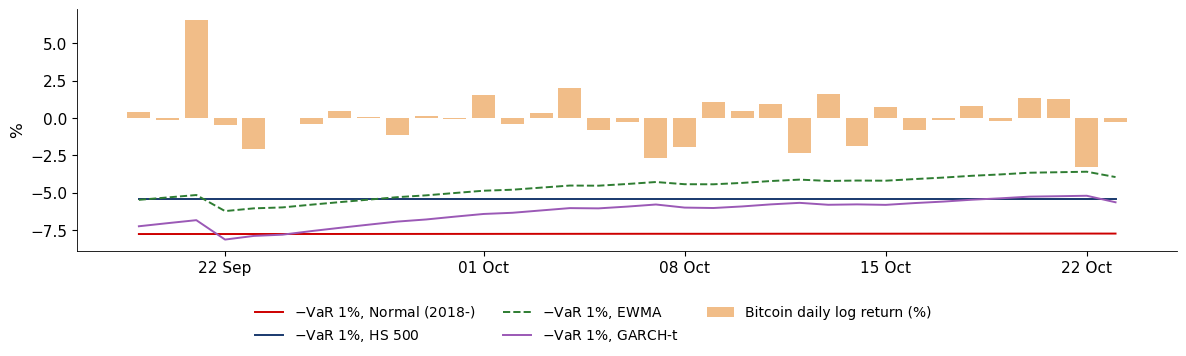

Bitcoin 1-day VaR 1%, 35 days; expected hits = 0.35
worst day 2026-10-22: -3.27%, which is 0.63 of that day's GARCH-t VaR
18 Sep forecast for 19 Sep: GARCH-t VaR 1% = 7.23%; realised return on 19 Sep = +0.41%


,mean VaR 1% (%),min VaR (%),max VaR (%),hits,"mean capital, USD per 1m"
Normal (2018-),7.73,7.72,7.75,0,74427.81
HS 500,5.43,5.43,5.43,0,52854.34
EWMA,4.66,3.59,6.22,0,45500.23
GARCH-t,6.28,5.19,8.12,0,60870.50


In [22]:
full_o = (100 * np.log(daily('BTC-USD.CC', T1)).diff()).dropna().loc['2015-01-01':]
oos = full_o.loc[T0 + pd.Timedelta(days=1):]
prm = fits['Bitcoin'].params; nu_b = prm['nu']; sc_b = np.sqrt((nu_b - 2) / nu_b)
sigG = onestep['Bitcoin'][1]
loc_o = {t_: i for i, t_ in enumerate(full_o.index)}
v = full_o.iloc[:250].var(); ewv = {}
for t_, x in full_o.items():
    ewv[t_] = v; v = lam * v + (1 - lam) * x ** 2
VO = pd.DataFrame(index=oos.index)
for t_ in oos.index:
    i = loc_o[t_]; w500 = full_o.iloc[i - 500:i]
    hist = full_o.loc['2018-01-01':full_o.index[i - 1]]
    VO.loc[t_, 'Normal (2018-)'] = -(hist.mean() + hist.std() * z1)
    VO.loc[t_, 'HS 500'] = -w500.quantile(p1)
    VO.loc[t_, 'EWMA'] = -np.sqrt(ewv[t_]) * z1
    VO.loc[t_, 'GARCH-t'] = -(prm['mu'] + sigG[t_] * sc_b * stats.t.ppf(p1, nu_b))

fig, ax = plt.subplots(figsize=(12, 3.6))
ax.bar(oos.index, oos, width=0.8, color=BTC, alpha=0.6, label='Bitcoin daily log return (%)')
for m_, col, ls in [('Normal (2018-)', RED, '-'), ('HS 500', BLUE, '-'), ('EWMA', GREEN, '--'), ('GARCH-t', ETH, '-')]:
    ax.plot(VO.index, -VO[m_], color=col, ls=ls, lw=1.4, label=f'$-$VaR 1%, {m_}')
ax.set_ylabel('%')
import matplotlib.dates as mdates
ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=[1, 8, 15, 22]))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
legend_below(fig, ncol=3); fig.tight_layout(rect=(0, 0.17, 1, 1))
save_fig(fig, 'ba_oos_var_btc')

print(f'Bitcoin 1-day VaR 1%, {len(oos)} days; expected hits = {p1 * len(oos):.2f}')
w_ = oos.idxmin()
print(f'worst day {w_.date()}: {oos.min():.2f}%, which is {-oos.min() / VO.loc[w_, "GARCH-t"]:.2f} of that day\'s GARCH-t VaR')
print(f'18 Sep forecast for 19 Sep: GARCH-t VaR 1% = {VO["GARCH-t"].iloc[0]:.2f}%; realised return on 19 Sep = {oos.iloc[0]:+.2f}%')
pd.DataFrame({'mean VaR 1% (%)': VO.mean(), 'min VaR (%)': VO.min(), 'max VaR (%)': VO.max(),
              'hits': (oos.values[:, None] < -VO.values).sum(axis=0),
              'mean capital, USD per 1m': (1e6 * (1 - np.exp(-VO / 100))).mean()}).round(2)

### How much can 35 days tell us?

If the VaR 1% is correct, the number of hits in $n = 35$ days is $X \sim \mathrm{Bin}(35, 0.01)$, a binomial distribution.
The cell computes the probability of zero hits, the Kupiec statistic for zero hits, the probability of zero hits for a model whose true hit rate is 2%, and the number of days needed to detect a 2% hit rate against 1% with probability 0.8 (one-sided exact binomial test at the 5% level).

In [23]:
n_w = 35
LR0 = -2 * n_w * np.log(1 - p1)
print(f'P(X = 0) for a correct VaR 1%: 0.99^35 = {(1 - p1) ** n_w:.3f}')
print(f'LR_uc for zero hits = -2 x 35 ln 0.99 = {LR0:.2f}, p-value = {stats.chi2.sf(LR0, 1):.2f}')
print(f'P(X = 0) when the true hit rate is 2%: 0.98^35 = {0.98 ** n_w:.3f}')
for n_ in range(100, 3000):
    c = stats.binom.ppf(0.95, n_, p1) + 1                  # smallest c with P(X >= c | 1%) <= 0.05: reject if X >= c
    while stats.binom.sf(c - 2, n_, p1) <= 0.05:
        c -= 1
    if stats.binom.sf(c - 1, n_, 0.02) >= 0.8:
        print(f'days needed to detect a 2% hit rate with power 0.8: {n_} (reject if hits >= {int(c)})')
        break
ratio = VO['GARCH-t'].mean() / VO['EWMA'].mean()
print(f'mean GARCH-t VaR / mean EWMA VaR over the window = {ratio:.2f}')

P(X = 0) for a correct VaR 1%: 0.99^35 = 0.703
LR_uc for zero hits = -2 x 35 ln 0.99 = 0.70, p-value = 0.40
P(X = 0) when the true hit rate is 2%: 0.98^35 = 0.493
days needed to detect a 2% hit rate with power 0.8: 905 (reject if hits >= 15)
mean GARCH-t VaR / mean EWMA VaR over the window = 1.35


Zero hits in five weeks is no evidence for any of the four methods: all four "pass".
They differ in the capital they require; the long backtest, not this window, tells us which method is right.
The whole predicted density can be checked as well, not only the hits (see the further material below).

## 6. Further material

### Is there a leverage effect?

The GJR-GARCH model lets negative shocks raise volatility more than positive ones:

$$ \sigma_t^2 = \omega + \big(\alpha + \gamma\,\mathbb 1\{\varepsilon_{t-1} < 0\}\big)\varepsilon_{t-1}^2 + \beta\,\sigma_{t-1}^2 . $$

$\gamma > 0$ is the leverage effect; the persistence becomes $\alpha + \beta + \gamma/2$ (a negative shock occurs half of the time for symmetric $z_t$).
We test $\gamma = 0$ with the likelihood ratio $\mathrm{LR} = 2(\ell_{\text{GJR}} - \ell_{\text{GARCH}}) \sim \chi^2_1$ (5% critical value 3.84) and compare the Akaike information criterion $\mathrm{AIC} = 2k - 2\ell$, with $k$ the number of parameters: a lower AIC means a better fit after a penalty for the extra parameter $\gamma$.

In [24]:
lev = {}
for k in ASSETS:
    j_, g_ = gjr[k], fits[k]
    LR = 2 * (j_.loglikelihood - g_.loglikelihood)
    lev[k] = {'gamma (GJR)': j_.params['gamma[1]'], 't(gamma)': j_.tvalues['gamma[1]'],
              'persistence alpha + beta + gamma/2': j_.params['alpha[1]'] + j_.params['beta[1]'] + j_.params['gamma[1]'] / 2, 'LR': LR,
              'p-value': stats.chi2.sf(LR, 1), 'AIC GARCH': g_.aic, 'AIC GJR': j_.aic}
pd.DataFrame(lev).T.round(3)

,gamma (GJR),t(gamma),persistence alpha + beta + gamma/2,LR,p-value,AIC GARCH,AIC GJR
Bitcoin,0.013,0.721,1.000,0.685,0.408,15518.371,15519.687
Ethereum,0.028,0.737,0.998,1.191,0.275,17492.945,17493.754
S&P 500,0.249,6.252,0.968,75.892,0.000,5901.539,5827.647
Gold,-0.060,-3.209,0.995,14.266,0.000,5980.420,5968.154


For the S&P 500 falls raise volatility much more than rises, and GJR is preferred by both LR and AIC.
For gold $\hat\gamma < 0$: rises raise volatility more than falls.
For crypto no asymmetry is detected, and AIC prefers the plain GARCH(1,1).

### News impact curves

The news impact curve shows today's volatility as a function of yesterday's shock $\varepsilon_{t-1}$, holding yesterday's variance at its sample median (GJR-GARCH-t).
The dashed red line is a symmetric curve with the same average reaction, $\alpha + \gamma/2$.

S&P 500  today's volatility after a -3% day: 27.0% a year; after a +3% day: 12.9% a year
Bitcoin  today's volatility after a -3% day: 59.8% a year; after a +3% day: 59.4% a year


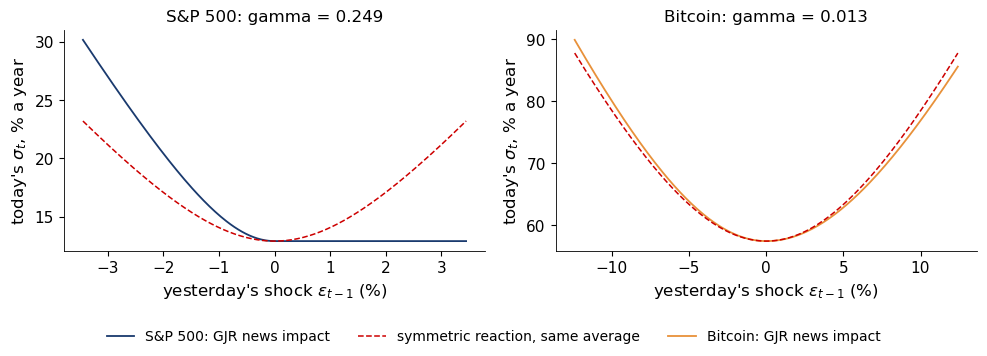

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for a_, k in [(ax[0], 'S&P 500'), (ax[1], 'Bitcoin')]:
    pj = gjr[k].params; A = ASSETS[k][1]
    s2 = np.median(gjr[k].conditional_volatility ** 2)
    nic = lambda e: pj['omega'] + (pj['alpha[1]'] + pj['gamma[1]'] * (e < 0)) * e ** 2 + pj['beta[1]'] * s2
    e = np.linspace(-4, 4, 201) * np.sqrt(s2)
    nic_s = pj['omega'] + (pj['alpha[1]'] + pj['gamma[1]'] / 2) * e ** 2 + pj['beta[1]'] * s2
    a_.plot(e, np.sqrt(nic(e) * A), color=ASSETS[k][2], label=f'{k}: GJR news impact')
    a_.plot(e, np.sqrt(nic_s * A), color=RED, ls='--', lw=1.1, label=('symmetric reaction, same average' if k == 'S&P 500' else None))
    a_.set_xlabel(r"yesterday's shock $\varepsilon_{t-1}$ (%)"); a_.set_ylabel(r"today's $\sigma_t$, % a year")
    a_.set_title(f"{k}: gamma = {pj['gamma[1]']:.3f}")
    print(f'{k:8s} today\'s volatility after a -3% day: {np.sqrt(nic(-3.0) * A):.1f}% a year; '
          f'after a +3% day: {np.sqrt(nic(3.0) * A):.1f}% a year')
legend_below(fig, ncol=3); fig.tight_layout(rect=(0, 0.1, 1, 1))
save_fig(fig, 'ba_l3_news_impact')

### Diagnostics: Normal or Student-t errors?

Quantile–quantile plots of the Bitcoin standardised residuals $\hat z_t$ against the Normal (left) and against the fitted Student-t rescaled to unit variance (right).
If the distribution is right, the points lie on the 45-degree line.

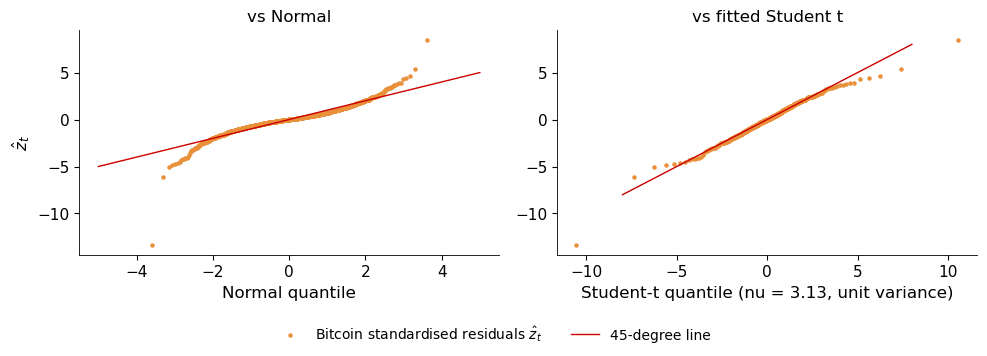

most extreme residual: z = -13.3 on 2020-03-12; matching Student-t quantile = -10.5


In [26]:
g = fits['Bitcoin']; nu = g.params['nu']
zs = g.std_resid.dropna()
z = np.sort(zs.values)
pp = (np.arange(1, len(z) + 1) - 0.5) / len(z)
qn = stats.norm.ppf(pp)
qt = stats.t.ppf(pp, nu) * np.sqrt((nu - 2) / nu)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].scatter(qn, z, s=5, color=BTC, label=r'Bitcoin standardised residuals $\hat z_t$')
ax[0].plot([-5, 5], [-5, 5], color=RED, lw=1, label='45-degree line')
ax[0].set_xlabel('Normal quantile'); ax[0].set_ylabel(r'$\hat z_t$'); ax[0].set_title('vs Normal')
ax[1].scatter(qt, z, s=5, color=BTC)
ax[1].plot([-8, 8], [-8, 8], color=RED, lw=1)
ax[1].set_xlabel(f'Student-t quantile (nu = {nu:.2f}, unit variance)'); ax[1].set_title('vs fitted Student t')
legend_below(fig, ncol=2); fig.tight_layout(rect=(0, 0.1, 1, 1))
save_fig(fig, 'ba_l3_qq_resid')
print(f'most extreme residual: z = {zs.min():.1f} on {zs.idxmin().date()}; matching Student-t quantile = {qt[0]:.1f}')

The Normal fails in both tails. The Student-t fits well, except for the single most extreme day in March 2020.

### The traffic light through time

The number of hits in the last 250 days for each method in the backtest, with the Basel green, amber and red zones in the background.

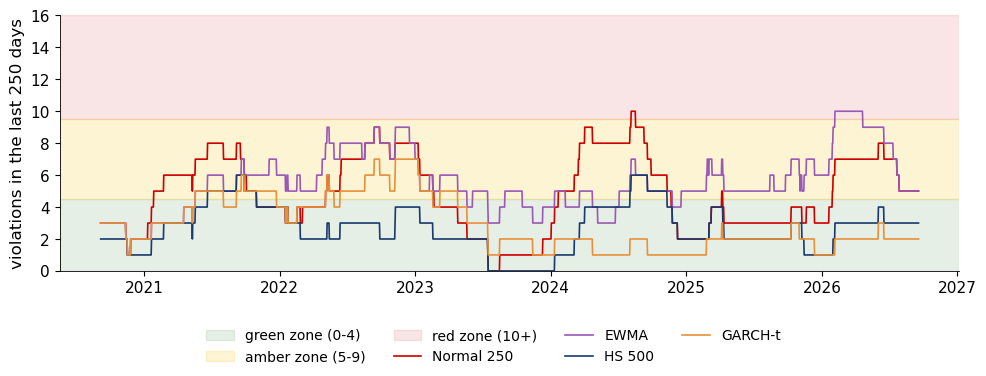

,share of days in amber or red zone (%),share of days in red zone (%)
Normal 250,50.3,0.5
EWMA,75.6,3.4
HS 500,10.5,0.0
GARCH-t,22.9,0.0


In [27]:
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.axhspan(0, 4.5, color=GREEN, alpha=0.12, label='green zone (0-4)')
ax.axhspan(4.5, 9.5, color='#F1C40F', alpha=0.18, label='amber zone (5-9)')
ax.axhspan(9.5, 16, color=RED, alpha=0.10, label='red zone (10+)')
zones = {}
for m_, col in [('Normal 250', RED), ('EWMA', ETH), ('HS 500', BLUE), ('GARCH-t', BTC)]:
    roll = (test < -pred[m_]).astype(int).rolling(250).sum().dropna()
    ax.plot(roll.index, roll, color=col, lw=1.2, label=m_)
    zones[m_] = {'share of days in amber or red zone (%)': 100 * (roll >= 5).mean(),
                 'share of days in red zone (%)': 100 * (roll >= 10).mean()}
ax.set_ylim(0, 16); ax.set_ylabel('violations in the last 250 days')
legend_below(fig, ncol=4); fig.tight_layout(rect=(0, 0.16, 1, 1))
save_fig(fig, 'ba_l3_traffic_light')
pd.DataFrame(zones).T.round(1)

A model can pass a full-sample test and still spend long periods in the amber zone: it has to be monitored continuously.

### Euler risk contributions

For a portfolio with weights $w$ and covariance matrix $\Sigma$, the return is $r_p = w^\top r$ and the volatility $\sigma_p = \sqrt{w^\top\Sigma w}$.
Since $\sigma_p$ is homogeneous of degree 1 in $w$, Euler's theorem splits it into risk contributions (RC):

$$ \sigma_p = \sum_i w_i\frac{\partial\sigma_p}{\partial w_i} = \sum_i \mathrm{RC}_i, \qquad \mathrm{RC}_i = \frac{w_i(\Sigma w)_i}{\sigma_p}. $$

The same holds for ES; with historical data, $\mathrm{ES}_p = \sum_i \mathrm{RC}^{ES}_i$ with $\mathrm{RC}^{ES}_i = -\mathrm{E}\big[w_i r_i \mid r_p \le q_p(r_p)\big]$.
The ratio $\mathrm{RC}_i/\sigma_p$ is the share of risk due to asset $i$, to be compared with its weight $w_i$.
The minimum-variance (MV) portfolio is $w^{\mathrm{MV}} = \Sigma^{-1}\mathbf 1/(\mathbf 1^\top\Sigma^{-1}\mathbf 1)$.

We use the S&P 500, long US Treasuries (the exchange-traded fund TLT, iShares 20+ Year Treasury Bond ETF) and Bitcoin on their common trading days, 2018–2026.

- S&P 500: the index GSPC is a price index, so dividends are not included (no total-return series is in the course data).
- TLT: the adjusted close, which reinvests the fund's distributions, so it is a total return.
- Daily **simple** returns $R_t = P_t/P_{t-1} - 1$: with weights rebalanced daily, the portfolio return is exactly $w^\top R_t$ (a weighted sum of log returns is not the log return of a portfolio).

### Worked example: Euler contributions with two assets

95% S&P 500 and 5% Bitcoin, with the annualised volatilities and the correlation of the sample (rounded as in the lecture).

In [28]:
def adjusted(sym, end):
    # adjusted close (distributions reinvested) from data/market/<sym>.csv
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['adjusted_close']
    return p[p > 0].loc[:end]


px = pd.concat({'S&P 500': daily('GSPC.INDX', END), 'Treasuries (TLT)': adjusted('TLT.US', END),
                'Bitcoin': daily('BTC-USD.CC', END)}, axis=1).dropna()
X = (100 * px.pct_change()).dropna().loc['2018-01-01':]          # daily simple returns, %
print(f'common days: {len(X)}, {X.index[0].date()} - {X.index[-1].date()}')
nav = (1 + X / 100).cumprod()                                     # net asset value of 1 USD invested on 2 Jan 2018
yrs = (X.index[-1] - X.index[0]).days / 365.25
print('compound growth of the net asset value (% a year):', (100 * (nav.iloc[-1] ** (1 / yrs) - 1)).round(1).to_dict())

s1 = round(X['S&P 500'].std() * np.sqrt(252), 1); s2_ = round(X['Bitcoin'].std() * np.sqrt(252), 1)
rho = round(X['S&P 500'].corr(X['Bitcoin']), 2)
w2 = np.array([0.95, 0.05])
S2 = np.array([[s1 ** 2, rho * s1 * s2_], [rho * s1 * s2_, s2_ ** 2]])
sp = np.sqrt(w2 @ S2 @ w2)
rc = w2 * (S2 @ w2) / sp
print(f'sigma S&P 500 = {s1}% a year, sigma Bitcoin = {s2_}% a year, correlation = {rho}')
print(f'portfolio variance = {sp ** 2:.1f}, portfolio volatility = {sp:.2f}% a year')
print(f'RC S&P 500 = {rc[0]:.2f} points ({100 * rc[0] / sp:.1f}% of the risk); '
      f'RC Bitcoin = {rc[1]:.2f} points ({100 * rc[1] / sp:.1f}% of the risk); sum = {rc.sum():.2f}')

common days: 2190, 2018-01-02 - 2026-09-18
compound growth of the net asset value (% a year): {'S&P 500': 12.8, 'Treasuries (TLT)': -2.2, 'Bitcoin': 21.7}
sigma S&P 500 = 19.2% a year, sigma Bitcoin = 63.3% a year, correlation = 0.29
portfolio variance = 376.2, portfolio volatility = 19.40% a year
RC S&P 500 = 18.02 points (92.9% of the risk); RC Bitcoin = 1.38 points (7.1% of the risk); sum = 19.40


Bitcoin carries about 7% of the risk with 5% of the money.

### A 60/40 portfolio with Bitcoin

The S&P 500 and Treasuries are held in proportion 60/40, plus a Bitcoin weight from 0 to 10%.
For each weight the table gives the annualised volatility, the historical ES 2.5% of the daily simple portfolio return, and Bitcoin's share of each (Euler contributions).

In [29]:
S = X.cov().values
rows = {}
for wb in [0, 0.01, 0.025, 0.05, 0.10]:
    w = np.array([0.6 * (1 - wb), 0.4 * (1 - wb), wb])
    sp = np.sqrt(w @ S @ w)
    rc = w * (S @ w) / sp
    rp = X.values @ w
    tail = rp <= np.quantile(rp, p25)
    es = -rp[tail].mean()
    esc = -(X.values[tail] * w).mean(axis=0)
    rows[100 * wb] = {'volatility (% a year)': sp * np.sqrt(252), 'ES 2.5% (%, daily)': es,
                      'Bitcoin share of volatility (%)': 100 * rc[2] / sp, 'Bitcoin share of ES (%)': 100 * esc[2] / es + 0.0}
P_ = pd.DataFrame(rows).T
P_.index.name = 'Bitcoin weight (%)'

wmv = np.linalg.solve(S, np.ones(3)); wmv /= wmv.sum()
print('minimum-variance weights (%):', {c: round(float(100 * w_), 1) for c, w_ in zip(X.columns, wmv)})
print('correlations of daily returns:'); print(X.corr().round(2).to_string()); print()
P_.round(2)

minimum-variance weights (%): {'S&P 500': 40.5, 'Treasuries (TLT)': 59.6, 'Bitcoin': -0.2}
correlations of daily returns:
                  S&P 500  Treasuries (TLT)  Bitcoin
S&P 500              1.00             -0.14     0.29
Treasuries (TLT)    -0.14              1.00    -0.02
Bitcoin              0.29             -0.02     1.00



,volatility (% a year),"ES 2.5% (%, daily)",Bitcoin share of volatility (%),Bitcoin share of ES (%)
Bitcoin weight (%),,,,
0.0,12.25,2.26,0.00,0.00
1.0,12.31,2.29,1.59,2.04
2.5,12.45,2.32,4.81,5.28
5.0,12.83,2.40,11.94,11.46
10.0,14.08,2.60,29.45,26.87


A 5% Bitcoin weight carries about 12% of the portfolio volatility; a 10% weight about 29%.
The minimum-variance portfolio puts a slightly negative weight on Bitcoin: Bitcoin does not reduce risk here.

### Risk share against weight

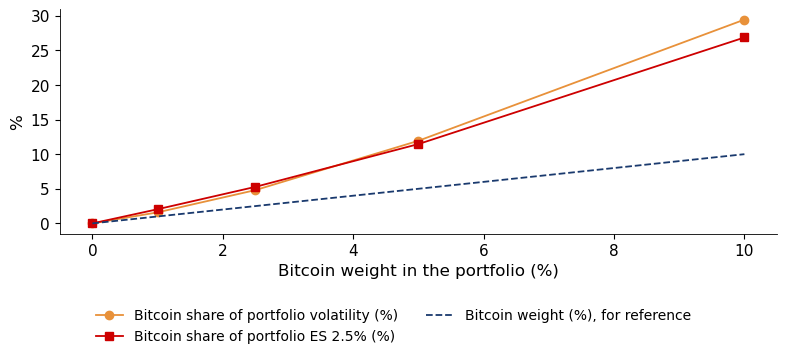

Bitcoin share of volatility / Bitcoin weight: {1.0: 1.59, 2.5: 1.92, 5.0: 2.39, 10.0: 2.94}


In [30]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(P_.index, P_['Bitcoin share of volatility (%)'], marker='o', color=BTC, label='Bitcoin share of portfolio volatility (%)')
ax.plot(P_.index, P_['Bitcoin share of ES (%)'], marker='s', color=RED, label='Bitcoin share of portfolio ES 2.5% (%)')
ax.plot(P_.index, P_.index, color=BLUE, ls='--', label='Bitcoin weight (%), for reference')
ax.set_xlabel('Bitcoin weight in the portfolio (%)'); ax.set_ylabel('%')
legend_below(fig, ncol=2); fig.tight_layout(rect=(0, 0.16, 1, 1))
save_fig(fig, 'ba_l3_riskcontrib')
ratio = (P_['Bitcoin share of volatility (%)'] / P_.index.to_series()).iloc[1:]
print('Bitcoin share of volatility / Bitcoin weight:', ratio.round(2).to_dict())

The risk share grows faster than the weight, from 1.6 times the weight at 1% to 2.9 times at 10%.
A position limit for crypto should therefore be set on its risk contribution, not on its weight.

### Does Bitcoin improve the efficient frontier?

Long-only minimum-variance frontiers, with and without Bitcoin, from the annualised means (daily mean $\times 252$) and covariances of the daily simple returns on the common days 2018–2026.

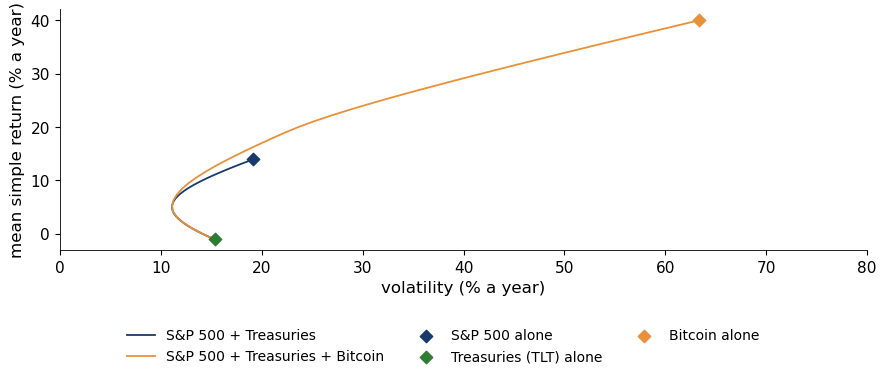

,mean simple return (% a year),volatility (% a year),compound NAV growth (% a year)
S&P 500,13.9,19.2,12.8
Treasuries (TLT),-1.1,15.3,-2.2
Bitcoin,40.0,63.3,21.7


In [31]:
from scipy.optimize import minimize
mu_a = X.mean().values * 252 / 100; S_a = X.cov().values * 252 / 1e4


def frontier(ix):
    # long-only minimum variance for 40 target means between the lowest and highest asset mean
    mus = np.linspace(mu_a[ix].min(), mu_a[ix].max(), 40); vols = []
    for target in mus:
        n_ = len(ix)
        cons = [{'type': 'eq', 'fun': lambda w: w.sum() - 1}, {'type': 'eq', 'fun': lambda w, t=target: w @ mu_a[ix] - t}]
        r_ = minimize(lambda w: w @ S_a[np.ix_(ix, ix)] @ w, np.ones(n_) / n_, constraints=cons,
                      bounds=[(0, 1)] * n_, method='SLSQP')
        vols.append(np.sqrt(r_.fun) if r_.success else np.nan)
    return np.array(vols), mus


v2, m2 = frontier([0, 1]); v3, m3 = frontier([0, 1, 2])
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(100 * v2, 100 * m2, color=BLUE, label='S&P 500 + Treasuries')
ax.plot(100 * v3, 100 * m3, color=BTC, label='S&P 500 + Treasuries + Bitcoin')
for i_, (nm, col) in enumerate([('S&P 500', BLUE), ('Treasuries (TLT)', GREEN), ('Bitcoin', BTC)]):
    ax.scatter(100 * np.sqrt(S_a[i_, i_]), 100 * mu_a[i_], color=col, s=40, zorder=5, marker='D', label=f'{nm} alone')
ax.set_xlabel('volatility (% a year)'); ax.set_ylabel('mean simple return (% a year)'); ax.set_xlim(0, 80)
legend_below(fig, ncol=3); fig.tight_layout(rect=(0, 0.16, 1, 1))
save_fig(fig, 'ba_l3_frontier')
pd.DataFrame({'mean simple return (% a year)': 100 * mu_a, 'volatility (% a year)': 100 * np.sqrt(np.diag(S_a)),
              'compound NAV growth (% a year)': 100 * (nav.iloc[-1] ** (1 / yrs) - 1)}, index=X.columns).round(1)

Adding Bitcoin extends the frontier only at high volatility; at the low-risk end the two frontiers coincide.
The means are in-sample, so the chart gives an upper bound on the benefit of adding Bitcoin.

### Out of sample: one-step volatility forecasts, day by day

For each asset: the realised absolute return $|r_t|$, the one-step GARCH-t forecast $\hat\sigma_{t|t-1}$ with the parameters frozen on 18 September, the forecast path made on 18 September, $\sqrt{\mathrm{E}_T\sigma^2_{T+h}}$, and the realised root mean square (RMS) return of the window. All in % a day.

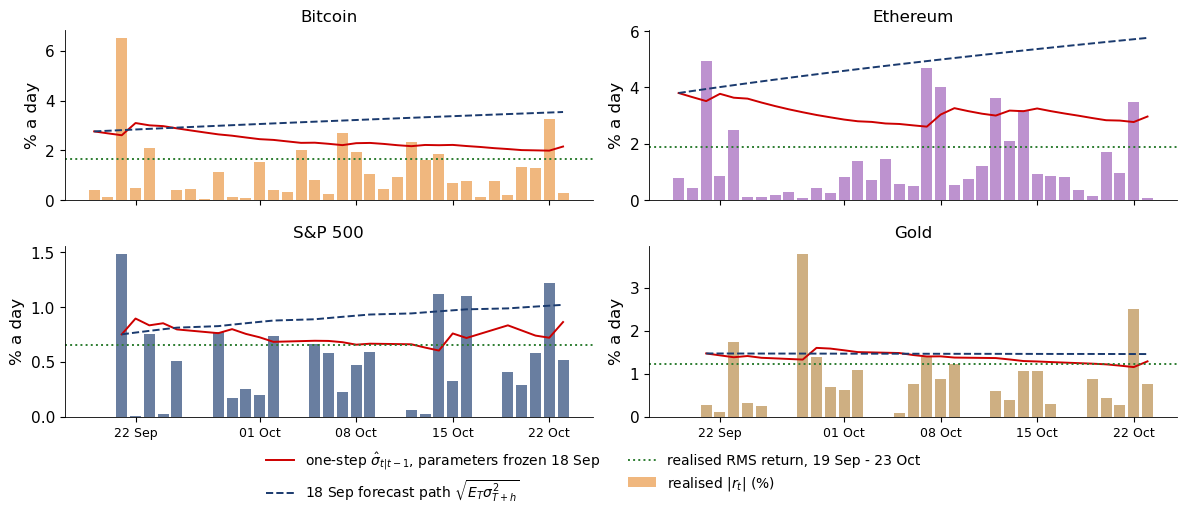

Bitcoin largest daily return in the window: +6.51% on 2026-09-21
Bitcoin persistence alpha + beta = 1.0000000000 (at the bound 1), omega = 0.144
Ethereum persistence alpha + beta = 1.0000000000 (at the bound 1), omega = 0.550


In [32]:
fig, axs = plt.subplots(2, 2, figsize=(12, 5.2), sharex=True)
for ax, (k, (oos_k, sig, A, ewk, const, prm_k)) in zip(axs.flat, onestep.items()):
    ax.bar(oos_k.index, oos_k.abs(), width=0.8, color=ASSETS[k][2], alpha=0.65, label=('realised $|r_t|$ (%)' if k == 'Bitcoin' else None))
    ax.plot(sig.index, sig, color=RED, lw=1.4, label=(r'one-step $\hat\sigma_{t|t-1}$, parameters frozen 18 Sep' if k == 'Bitcoin' else None))
    ax.plot(paths[k].index, paths[k] / np.sqrt(A), color=BLUE, ls='--', lw=1.4,
            label=(r'18 Sep forecast path $\sqrt{E_T\sigma^2_{T+h}}$' if k == 'Bitcoin' else None))
    ax.axhline(np.sqrt((oos_k ** 2).mean()), color=GREEN, ls=':', lw=1.4, label=('realised RMS return, 19 Sep - 23 Oct' if k == 'Bitcoin' else None))
    ax.set_title(k); ax.set_ylabel('% a day'); ax.tick_params(axis='x', labelsize=9)
for ax in axs[1]:
    ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=[1, 8, 15, 22]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
legend_below(fig, ncol=2); fig.tight_layout(rect=(0, 0.11, 1, 1))
save_fig(fig, 'ba_oos_vol')
b = onestep['Bitcoin'][0]
print(f'Bitcoin largest daily return in the window: {b.max():+.2f}% on {b.idxmax().date()}')
for k in ['Bitcoin', 'Ethereum']:
    pr = fits[k].params
    print(f'{k} persistence alpha + beta = {pr["alpha[1]"] + pr["beta[1]"]:.10f} (at the bound 1), omega = {pr["omega"]:.3f}')

### Which forecast is best? QLIKE and Diebold–Mariano

The squared return $r_t^2$ is a noisy proxy of the variance $\sigma_t^2$. The quasi-likelihood (QLIKE) loss of a variance forecast $h_t$ is robust to that noise (Patton, 2011):

$$ L_t(h) = \ln h_t + r_t^2/h_t . $$

We compare GARCH-t with EWMA and with a constant (Normal, full-sample) variance by the loss difference $d_t = L_t(\text{GARCH}) - L_t(\text{other})$ and the Diebold–Mariano (DM) statistic $\mathrm{DM} = \bar d / \widehat{\mathrm{se}}_{\mathrm{HAC}}(\bar d)$, approximately $N(0,1)$.
HAC means heteroskedasticity- and autocorrelation-consistent (here with 4 lags). $\bar d > 0$ means that GARCH loses.

In [33]:
import statsmodels.api as sm


def dm_test(d):
    res = sm.OLS(d.values, np.ones(len(d))).fit(cov_type='HAC', cov_kwds={'maxlags': 4})
    return res.params[0], res.tvalues[0]


ql = {}
for k, (oos_k, sig, A, ewk, const, prm_k) in onestep.items():
    qlike = lambda s2: np.log(s2) + oos_k ** 2 / s2
    dG, dE, dC = qlike(sig ** 2), qlike(ewk), qlike(pd.Series(const, index=oos_k.index))
    (ge, tge), (gc, tgc) = dm_test(dG - dE), dm_test(dG - dC)
    ql[k] = {'mean QLIKE: GARCH-t': dG.mean(), 'mean QLIKE: EWMA': dE.mean(), 'mean QLIKE: constant (Normal)': dC.mean(),
             'GARCH vs EWMA: d bar': ge, 'GARCH vs EWMA: DM': tge, 'GARCH vs constant: d bar': gc, 'GARCH vs constant: DM': tgc}
pd.DataFrame(ql).round(3)

,Bitcoin,Ethereum,S&P 500,Gold
mean QLIKE: GARCH-t,2.232,2.655,0.220,1.480
mean QLIKE: EWMA,2.094,2.435,0.184,1.480
mean QLIKE: constant (Normal),2.667,3.152,0.670,1.431
GARCH vs EWMA: d bar,0.138,0.220,0.036,-0.000
GARCH vs EWMA: DM,1.974,2.992,0.830,-0.007
GARCH vs constant: d bar,-0.435,-0.497,-0.450,0.048
GARCH vs constant: DM,-4.110,-6.120,-3.500,0.320


A time-varying forecast beats the constant one clearly for Bitcoin, Ethereum and the S&P 500.
EWMA beats GARCH for Ethereum and, at the margin, for Bitcoin: it forgets faster, and after a calm month that helps.
Yet in the 2020–2026 backtest EWMA-Normal failed the VaR test: being good at the level of volatility is not being good at the tail.

### Was the density right? PIT and the Berkowitz test

The probability integral transform (PIT) $u_t = \hat F_{t|t-1}(r_t)$, the predicted distribution function evaluated at the realised return, is i.i.d. uniform on $(0,1)$ if the predicted density is right.
Berkowitz (2001) transforms it to $x_t = \Phi^{-1}(u_t)$, fits $x_t = c + \rho x_{t-1} + \sigma\varepsilon_t$, and tests $c = 0, \rho = 0, \sigma = 1$ with $\mathrm{LR} = 2(\ell_1 - \ell_0) \sim \chi^2_3$.
The Kolmogorov–Smirnov (KS) test compares the $u_t$ directly with the uniform distribution.

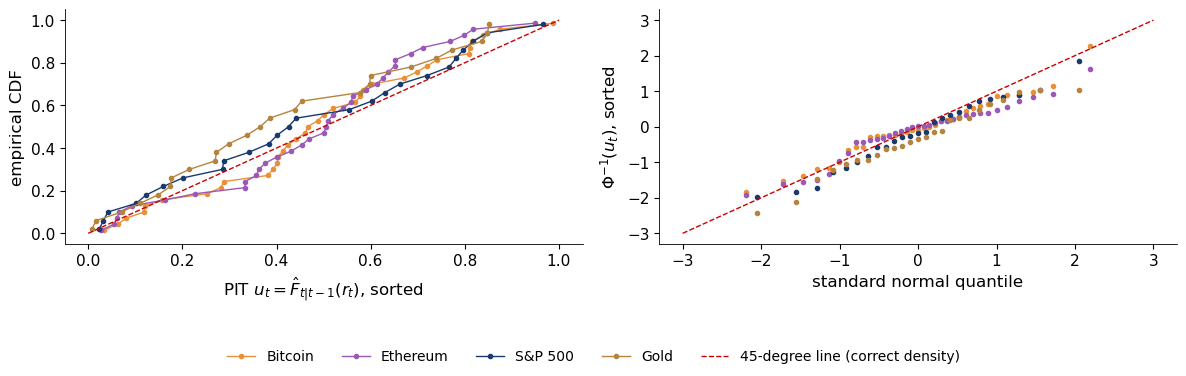

Gold worst day in the window: -3.78% on 2026-09-28


,Bitcoin,Ethereum,S&P 500,Gold
mean of x_t (should be 0),-0.047,-0.130,-0.177,-0.336
sd of x_t (should be 1),0.841,0.776,0.979,0.926
AR(1) rho of x_t,-0.187,-0.086,-0.047,-0.321
Berkowitz LR,3.159,4.796,2.359,5.593
Berkowitz p-value,0.368,0.187,0.501,0.133
KS D,0.125,0.176,0.119,0.186
KS p-value,0.604,0.203,0.833,0.310
GARCH-t VaR 1% hits,0.000,0.000,0.000,1.000
lowest z_t,-1.670,-1.827,-2.035,-2.891


In [34]:
pit_rows = {}
for k, (oos_k, sig, A, ewk, const, prm_k) in onestep.items():
    nu_k = prm_k['nu']; sc_k = np.sqrt((nu_k - 2) / nu_k)
    z_ = (oos_k - prm_k['mu']) / sig
    u = stats.t.cdf(z_ / sc_k, nu_k)
    x = stats.norm.ppf(np.clip(u, 1e-6, 1 - 1e-6))
    ar = sm.OLS(x[1:], sm.add_constant(x[:-1])).fit()
    ll1 = stats.norm.logpdf(x[1:], ar.fittedvalues, np.sqrt(ar.resid.var(ddof=0))).sum()
    ll0 = stats.norm.logpdf(x[1:]).sum()
    LRb = 2 * (ll1 - ll0); ks = stats.kstest(u, 'uniform')
    hit1 = int((oos_k < prm_k['mu'] + sig * sc_k * stats.t.ppf(p1, nu_k)).sum())
    pits[k] = (u, x)
    pit_rows[k] = {'mean of x_t (should be 0)': x.mean(), 'sd of x_t (should be 1)': x.std(ddof=1), 'AR(1) rho of x_t': ar.params[1],
                   'Berkowitz LR': LRb, 'Berkowitz p-value': stats.chi2.sf(LRb, 3), 'KS D': ks.statistic, 'KS p-value': ks.pvalue,
                   'GARCH-t VaR 1% hits': hit1, 'lowest z_t': z_.min()}

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for k, (u, x) in pits.items():
    col = ASSETS[k][2]
    ax[0].plot(np.sort(u), (np.arange(1, len(u) + 1) - 0.5) / len(u), color=col, marker='o', ms=3, lw=1, label=k)
    ax[1].plot(stats.norm.ppf((np.arange(1, len(x) + 1) - 0.5) / len(x)), np.sort(x), color=col, marker='o', ms=3, lw=0)
ax[0].plot([0, 1], [0, 1], color=RED, ls='--', lw=1, label='45-degree line (correct density)')
ax[0].set_xlabel(r'PIT $u_t = \hat F_{t|t-1}(r_t)$, sorted'); ax[0].set_ylabel('empirical CDF')
ax[1].plot([-3, 3], [-3, 3], color=RED, ls='--', lw=1)
ax[1].set_xlabel('standard normal quantile'); ax[1].set_ylabel(r'$\Phi^{-1}(u_t)$, sorted')
legend_below(fig, ncol=5); fig.tight_layout(rect=(0, 0.14, 1, 1))
save_fig(fig, 'ba_oos_pit')
g_ = onestep['Gold'][0]
print(f'Gold worst day in the window: {g_.min():.2f}% on {g_.idxmin().date()}')
pd.DataFrame(pit_rows).round(3)

Here CDF is the cumulative distribution function. For crypto the standard deviation of $x_t$ is below 1: the predicted densities were too wide, in line with the over-predicted volatility, but this is not significant in 35 days.
For gold no test rejects at 5%, although the mean of $x_t$ is negative (the forecasts missed the downward drift) and there was one VaR 1% hit, on Monday 28 September.

### The portfolio out of sample: correlation is the unstable input

The 60/40 S&P 500/Treasuries portfolio with a Bitcoin weight of 0, 5% and 10%: volatility and Bitcoin's share of risk predicted from the 2018–2026 covariance matrix and realised over the 25 new trading days.

In [35]:
pxo = pd.concat({'S&P 500': daily('GSPC.INDX', T1), 'Treasuries (TLT)': adjusted('TLT.US', T1),
                 'Bitcoin': daily('BTC-USD.CC', T1)}, axis=1).dropna()
XA = (100 * pxo.pct_change()).dropna().loc['2018-01-01':]           # daily simple returns, %
Xi, Xo = XA.loc[:T0], XA.loc[T0 + pd.Timedelta(days=1):]
Si, So = Xi.cov().values, Xo.cov().values
port = {}
for wb in [0, 0.05, 0.10]:
    w = np.array([0.6 * (1 - wb), 0.4 * (1 - wb), wb])
    spi, spo = np.sqrt(w @ Si @ w), np.sqrt(w @ So @ w)
    port[100 * wb] = {'volatility predicted (% a year)': spi * np.sqrt(252), 'volatility realised (% a year)': spo * np.sqrt(252),
                      'Bitcoin share of risk predicted (%)': 100 * w[2] * (Si @ w)[2] / spi ** 2,
                      'Bitcoin share of risk realised (%)': 100 * w[2] * (So @ w)[2] / spo ** 2}
print(f'new common trading days: {len(Xo)}')
print(f'Bitcoin volatility (% a year): {Xi["Bitcoin"].std() * np.sqrt(252):.1f} in 2018-2026, {Xo["Bitcoin"].std() * np.sqrt(252):.1f} over the new days')
print(f'correlation Bitcoin - S&P 500: {Xi.corr().loc["Bitcoin", "S&P 500"]:.2f} in 2018-2026, '
      f'{Xo.corr().loc["Bitcoin", "S&P 500"]:.2f} over the new days')
PO = pd.DataFrame(port).T; PO.index.name = 'Bitcoin weight (%)'
PO.round(1)

new common trading days: 25
Bitcoin volatility (% a year): 63.3 in 2018-2026, 31.4 over the new days
correlation Bitcoin - S&P 500: 0.29 in 2018-2026, 0.76 over the new days


,volatility predicted (% a year),volatility realised (% a year),Bitcoin share of risk predicted (%),Bitcoin share of risk realised (%)
Bitcoin weight (%),,,,
0.0,12.2,8.1,0.0,0.0
5.0,12.8,8.7,11.9,13.2
10.0,14.1,9.6,29.4,26.6


Bitcoin's own volatility halved in the window, yet its share of portfolio risk changed little: the higher correlation with the S&P 500 offset the lower volatility.
The share of asset $B$ is

$$ \text{share}_B = \frac{w_B\,(\Sigma w)_B}{w^\top\Sigma w}, \qquad (\Sigma w)_B = w_B\sigma_B^2 + \textstyle\sum_{j\ne B} w_j\rho_{Bj}\sigma_B\sigma_j , $$

so a risk budget is a forecast of the correlations, not only of the volatilities.